#load


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# import gdown
# file_id = "1J47YZhIyPnU5yof93_PrWIYcUL3sgWkO"
# url = f"https://drive.google.com/uc?id={file_id}"


# read data

In [6]:
import os
import scanpy as sc
import numpy as np
import pandas as pd
import scanpy.external as sce
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import gseapy as gp
from scipy.sparse import csr_matrix
import seaborn as sns
import anndata as ad
import pooch
# import sctour as sct
from gseapy.plot import barplot, dotplot
import harmonypy as hm
# import squidpy as sq


In [7]:
from pathlib import Path


In [8]:
os.chdir('/content/drive/MyDrive/pharynx')

#def

In [19]:
dot_map = LinearSegmentedColormap.from_list(
    "dot_map",
    [ '#306ead',"#B6D6E8",'#F7F7F7',"#F4B4A1","#b62530"]
)
#5799C6 #B6D6E8 #F7F7F7 #F4B4A1 #D6604D

In [20]:
def plot_cdotplot(
    adata_all,
    marker_genes_dict,
    cmap,
    groupby="subtype",
    name_map=None,
    figsize=(13, 5.6),
    dot_size=260,
    size_power=1.5,
    fontsize=14,
    legend_fontsize=12,
    show_subtype=True,
    save=None,
    dpi=600,
    show=True,
):
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import scanpy as sc
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle

    name_map = {} if name_map is None else name_map

    if groupby not in adata.obs:
        raise KeyError(f"adata.obs 中没有 {groupby!r}")

    if not isinstance(adata.obs[groupby].dtype, pd.CategoricalDtype):
        raise ValueError(
            f"adata.obs[{groupby!r}] 必须是 categorical 类型，"
            "其 categories 顺序需与 uns 中的颜色顺序一致。"
        )

    color_key = f"{groupby}_colors"
    if color_key not in adata.uns:
        raise KeyError(f"adata.uns 中没有 {color_key!r}")

    categories = adata.obs[groupby].cat.categories
    colors = adata.uns[color_key]

    if len(categories) != len(colors):
        raise ValueError("分组类别数与颜色数不一致")

    color_map = dict(zip(categories, colors))

    if not marker_genes_dict or any(
        len(gene_list) == 0 for gene_list in marker_genes_dict.values()
    ):
        raise ValueError("marker_genes_dict 及其中各组基因列表不能为空")

    missing = [
        name_map.get(group, group)
        for group in marker_genes_dict
        if name_map.get(group, group) not in color_map
    ]
    if missing:
        raise ValueError(
            f"以下 marker 分组未匹配到 {groupby}：{missing}；"
            "请通过 name_map 指定对应名称。"
        )

    genes = [
        gene
        for gene_list in marker_genes_dict.values()
        for gene in gene_list
    ]

    dp = sc.pl.dotplot(
        adata,
        genes,
        groupby=groupby,
        dendrogram=False,
        cmap=cmap,
        standard_scale="var",
        vmin=0,
        vmax=1,
        figsize=figsize,
        return_fig=True,
        show=False,
    )

    dp.style(
        cmap=cmap,
        dot_edge_color="none",
        dot_edge_lw=0,
        dot_min=0,
        dot_max=1,
        smallest_dot=0,
        largest_dot=dot_size,
        size_exponent=size_power,
    )
    dp.legend(show=False)
    dp.make_figure()

    ax = dp.get_axes()["mainplot_ax"]
    fig = ax.figure
    fig.set_size_inches(*figsize)
    fig.set_layout_engine(None)

    if show_subtype:
        ax.set_position([0.17, 0.36, 0.81, 0.56])
    else:
        ax.set_position([0.04, 0.36, 0.94, 0.56])
    ax.tick_params(axis="both", labelsize=fontsize, pad=4)

    for label in ax.get_xticklabels():
        label.set_rotation(90)
        label.set_fontstyle("italic")
        label.set_ha("center")

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    pos = ax.get_position()
    top_ax = fig.add_axes([
        pos.x0, pos.y1 + 0.012, pos.width, 0.025
    ])
    top_ax.set_xlim(ax.get_xlim())
    top_ax.set_ylim(0, 1)
    top_ax.axis("off")

    ticks = ax.get_xticks()
    step = ticks[1] - ticks[0] if len(ticks) > 1 else 1

    start = 0
    for group, gene_list in marker_genes_dict.items():
        n = len(gene_list)
        category = name_map.get(group, group)

        top_ax.add_patch(
            Rectangle(
                (ticks[start] - step / 2, 0),
                n * step,
                1,
                facecolor=color_map[category],
                edgecolor="none",
            )
        )
        start += n

    ax.tick_params(
        axis="y",
        labelleft=show_subtype,
        left=show_subtype,
        labelcolor="black",
    )

    for label in ax.get_yticklabels():
        label.set_color("black")

    legend_ax = fig.add_axes([0.60, 0.065, 0.38, 0.085])
    legend_ax.set_xlim(0, 1)
    legend_ax.set_ylim(0, 1)
    legend_ax.axis("off")

    y_center, y_label = 0.62, 0.12
    number_fontsize = legend_fontsize - 2

    legend_ax.text(
        0, y_center, "RNA level",
        fontsize=legend_fontsize, ha="left", va="center",
    )

    legend_ax.imshow(
        np.linspace(0, 1, 256)[None, :],
        extent=[0.19, 0.37, 0.50, 0.74],
        cmap=cmap,
        vmin=0,
        vmax=1,
        aspect="auto",
        origin="lower",
    )

    for x, text in [(0.19, "0"), (0.37, "1")]:
        legend_ax.text(
            x, y_label, text,
            fontsize=number_fontsize, ha="center", va="center",
        )

    legend_ax.text(
        0.405, y_center, "Percentage",
        fontsize=legend_fontsize, ha="left", va="center",
    )

    percentages = np.array([25, 50, 75])
    x_positions = [0.64, 0.705, 0.77]
    sizes = dot_size * (percentages / 100) ** size_power

    legend_ax.scatter(
        x_positions,
        [y_center] * 3,
        s=sizes,
        color="black",
        edgecolors="none",
    )

    for x, p in zip(x_positions, percentages):
        legend_ax.text(
            x, y_label, str(p),
            fontsize=number_fontsize, ha="center", va="center",
        )

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    text_right = max(
        t.get_window_extent(renderer).x1
        for t in legend_ax.texts
    )
    dot_center = legend_ax.transData.transform(
        (x_positions[-1], y_center)
    )[0]
    dot_radius = np.sqrt(sizes[-1]) / 2 * fig.dpi / 72

    legend_right = max(text_right, dot_center + dot_radius)
    shift = (
        ax.get_window_extent(renderer).x1 - legend_right
    ) / fig.bbox.width

    pos = legend_ax.get_position()
    legend_ax.set_position([
        pos.x0 + shift, pos.y0, pos.width, pos.height
    ])

    if save is not None:
        path = Path(save)
        path.parent.mkdir(parents=True, exist_ok=True)

        save_kwargs = dict(
            dpi=dpi,
            bbox_inches="tight",
            facecolor="white",
        )
        if path.suffix.lower() in {".tif", ".tiff"}:
            save_kwargs["pil_kwargs"] = {"compression": "tiff_lzw"}

        fig.savefig(path, **save_kwargs)

    if show:
        plt.show()

    return fig, dp

In [21]:
def plot_cumap(
    adata,
    color="subtype",
    palette=None,
    size=70,
    figsize=(8, 6),

    legend_loc="right margin",
    legend_fontsize=12,
    legend_fontweight="bold",
    legend_marker_size=70,

    title="",

    arrow_position=(0.08, 0.08, 0.22, 0.22),
    arrow_len=0.7,
    arrow_lw=2,
    arrow_headsize=14,
    axis_fontsize=10,

    save=None,
    dpi=600,
    show=True,
):

    from pathlib import Path

    import scanpy as sc
    import matplotlib.pyplot as plt

    # ============================================
    # ============================================
    if "X_umap" not in adata.obsm:
        raise ValueError(
            "adata.obsm 中没有 'X_umap'，请先计算 UMAP。"
        )

    # ============================================
    # ============================================
    fig, main_ax = plt.subplots(
        figsize=figsize
    )

    sc.pl.umap(
        adata,
        color=color,
        palette=palette,
        size=size,
        marker=".",
        frameon=False,

        legend_loc=legend_loc,
        legend_fontsize=legend_fontsize,
        legend_fontweight=legend_fontweight,

        title=title,

        ax=main_ax,
        show=False,
    )

    # ============================================
    # ============================================
    legend = main_ax.get_legend()

    if legend is not None:

        handles = getattr(
            legend,
            "legend_handles",
            None
        )

        if handles is None:
            handles = getattr(
                legend,
                "legendHandles",
                []
            )

        for handle in handles:

            if hasattr(handle, "set_sizes"):
                handle.set_sizes(
                    [legend_marker_size]
                )

            elif hasattr(handle, "set_markersize"):
                handle.set_markersize(
                    legend_marker_size ** 0.5
                )

    # ============================================
    # ============================================
    arrow_ax = fig.add_axes(
        arrow_position
    )

    arrow_ax.set_xlim(
        0,
        1.2
    )

    arrow_ax.set_ylim(
        0,
        1.2
    )

    arrow_ax.set_aspect(
        "equal"
    )

    arrow_ax.axis(
        "off"
    )

    x0, y0 = 0.2, 0.2

    x1 = x0 + arrow_len
    y1 = y0 + arrow_len

    arrowprops = dict(
        arrowstyle="-|>",
        lw=arrow_lw,
        color="black",
        mutation_scale=arrow_headsize,
    )

    # UMAP1
    arrow_ax.annotate(
        "",
        xy=(x1, y0),
        xytext=(x0, y0),
        arrowprops=arrowprops.copy(),
    )

    # UMAP2
    arrow_ax.annotate(
        "",
        xy=(x0, y1),
        xytext=(x0, y0),
        arrowprops=arrowprops.copy(),
    )

    # ============================================
    # ============================================
    arrow_ax.text(
        (x0 + x1) / 2,
        y0 - 0.12,
        "UMAP1",
        ha="center",
        va="top",
        fontsize=axis_fontsize,
    )

    # ============================================
    # ============================================
    arrow_ax.text(
        x0 - 0.12,
        (y0 + y1) / 2,
        "UMAP2",
        ha="right",
        va="center",
        fontsize=axis_fontsize,
        rotation=90,
    )

    # ============================================
    # ============================================
    if save is not None:

        path = Path(save)

        path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        save_kwargs = dict(
            dpi=dpi,
            bbox_inches="tight",
            facecolor="white",
        )

        if path.suffix.lower() in {
            ".tif",
            ".tiff"
        }:
            save_kwargs["pil_kwargs"] = {
                "compression": "tiff_lzw"
            }

        fig.savefig(
            path,
            **save_kwargs
        )

    # ============================================
    # ============================================
    if show:
        plt.show()

    return fig, main_ax, arrow_ax

In [22]:
dot_map = LinearSegmentedColormap.from_list(
    "dot_map",
    [ '#296baf','#efefee',"#b31a2c"]
)

In [23]:
from scipy import sparse
def anno_agent(
    adata,
    cell_type,
    cluster_key="leiden",
    min_pct_expr=0.25,
    min_fc=1,
    max_fdr=0.05,
    top_n=10,
):
    """
    Annotate cell types using top-ranked marker genes with filtering thresholds.
    """
    X_use = adata.raw.X if adata.raw is not None else adata.X
    var_names = adata.raw.var_names if adata.raw is not None else adata.var_names

    clusters = sorted(
        adata.obs[cluster_key].unique(),
        key=lambda x: float(x) if str(x).replace(".", "", 1).isdigit() else str(x),
    )
    output_lines = []

    for cluster in clusters:
        df = sc.get.rank_genes_groups_df(adata, group=cluster).set_index("names")

        mask = (adata.obs[cluster_key] == cluster).to_numpy()
        if sparse.issparse(X_use):
            frac = (X_use[mask] > 0).mean(axis=0).A1
        else:
            frac = (X_use[mask] > 0).mean(axis=0)

        expr_frac_series = pd.Series(frac, index=var_names)

        common = df.index.intersection(expr_frac_series.index)
        df = df.loc[common]
        df["pct_expr"] = expr_frac_series.loc[common]

        df = df[
            (df["pct_expr"] >= min_pct_expr)
            & (df["logfoldchanges"] >= np.log2(min_fc))
            & (df["pvals_adj"] <= max_fdr)
        ]

        df = df[~df.index.str.startswith(("MT-", "RPS", "RPL"))]

        top_genes = df.head(top_n).index.tolist()
        output_lines.append(f"{cluster}: {','.join(top_genes)}")

    return (
        f"Identify cell types of {cell_type} using the following markers. "
        "Identify one cell type for each row. Attention - Determine the Subtype, Characteristic Genes, Phenotype, and Predict Function for Each Cell Type."
        " Present the Results in a Tabular Format：\n"
        + "\n".join(output_lines)
    )

# quality control

In [ ]:
adata=sc.read_h5ad("/content/drive/MyDrive/pharynx/批次整合harmony.h5ad")

In [ ]:
adata

AnnData object with n_obs × n_vars = 71634 × 17613
    obs: 'sample', 'sampleid', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90', 'leiden_1.00', 'leiden

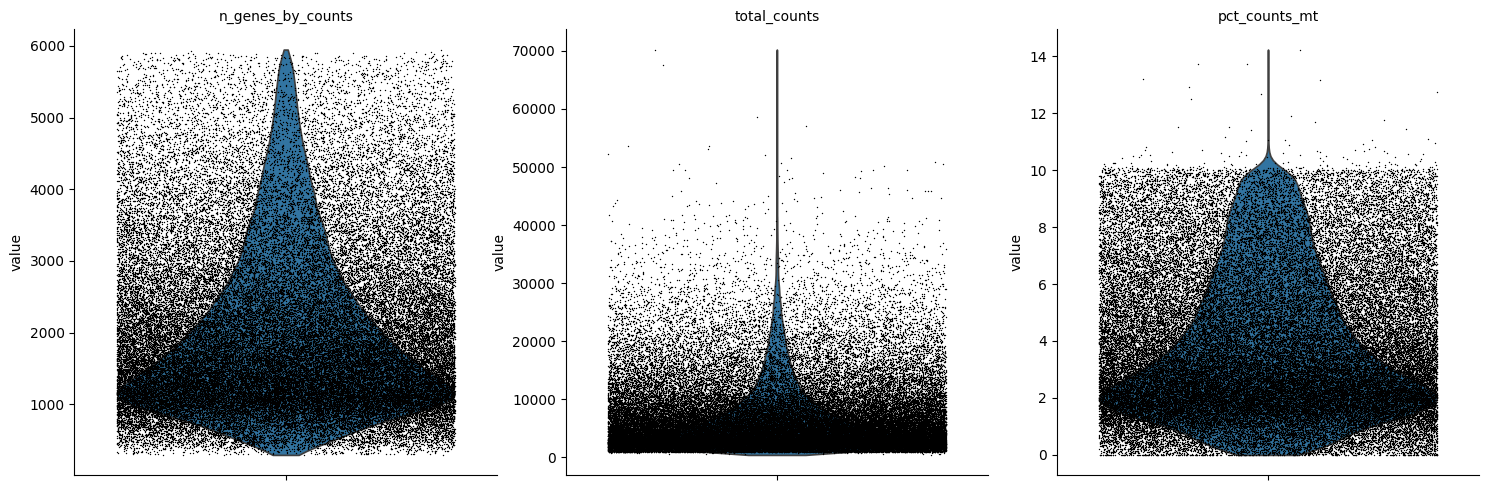

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt

adata.var["mt"] = adata.var_names.str.upper().str.startswith("MT-")

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    inplace=True
)

fg = sc.pl.violin(
    adata,
    keys=[
        "n_genes_by_counts",
        "total_counts",
        "pct_counts_mt"
    ],
    jitter=0.4,
    multi_panel=True,
    show=True
)



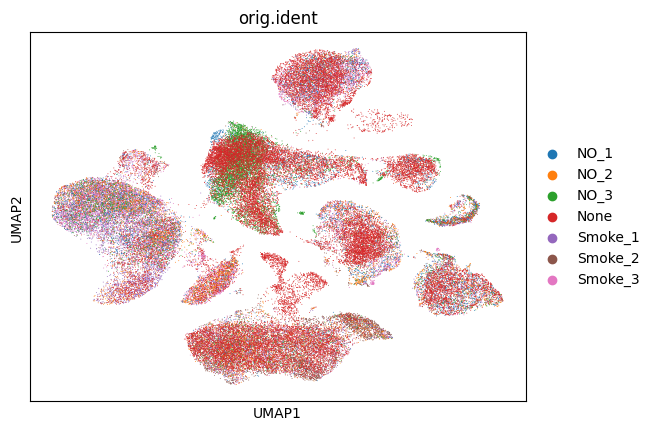

In [ ]:
sc.pl.umap(adata,color="orig.ident")

In [ ]:
adata = adata[
    adata.obs["orig.ident"].notna() &
    (adata.obs["orig.ident"].astype(str) != "None")
].copy()

adata.obs["orig.ident"] = (
    adata.obs["orig.ident"]
    .astype("category")
    .cat.remove_unused_categories()
)

In [ ]:
adata.obs["orig.ident"] = adata.obs["orig.ident"].replace({
    "NO_1": "No_1",
    "NO_2": "No_2",
    "NO_3": "No_3",
})
patient_colors = {
    "No_1":    "#238B45",
    "No_2":    "#66B27B",
    "No_3":    "#A8D5A2",

    "Smoke_1": "#D95F0E",
    "Smoke_2": "#F59B45",
    "Smoke_3": "#FBCB8B",
}
palette_patient = [
    patient_colors[x]
    for x in adata.obs["orig.ident"].cat.categories
]

adata.uns["orig.ident_colors"] = palette_patient

/tmp/ipykernel_1291/1984686747.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  adata.obs["orig.ident"] = adata.obs["orig.ident"].replace({


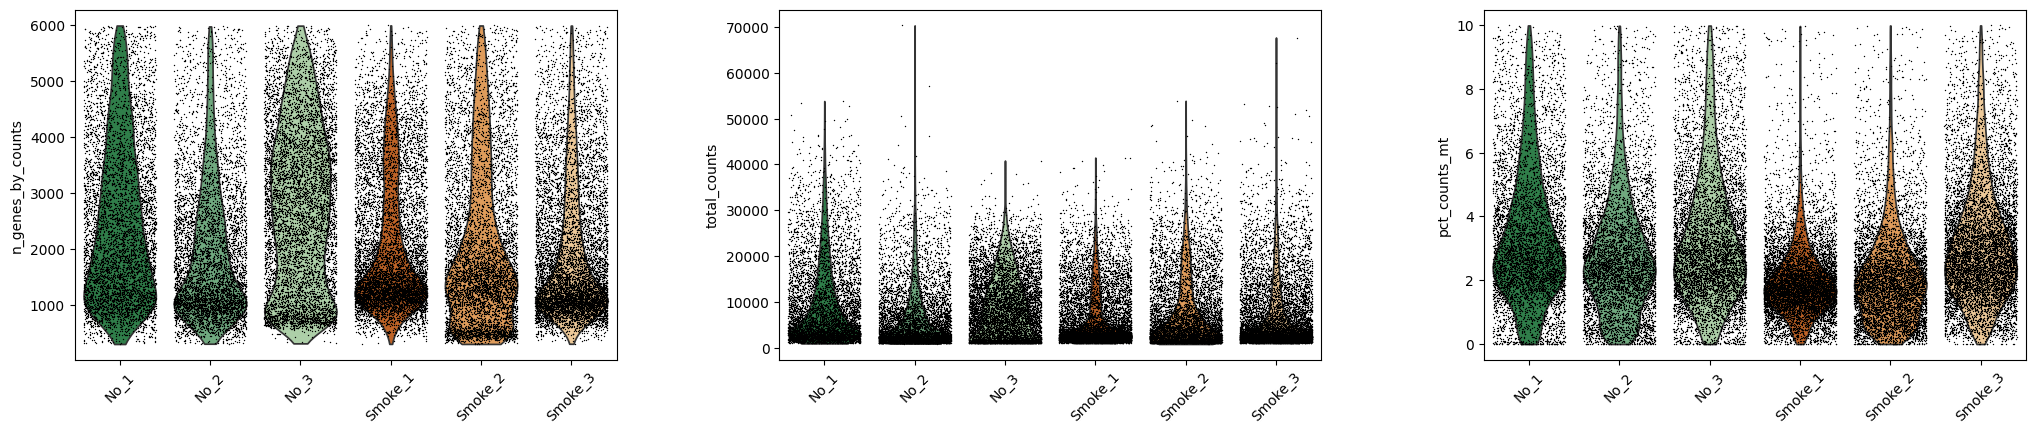

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt

sc.pl.violin(
    adata,
    keys=[
        "n_genes_by_counts",
        "total_counts",
        "pct_counts_mt"
    ],
    groupby="orig.ident",
    jitter=0.4,
    multi_panel=True,
    rotation=45,
    stripplot=True,
    show=False
)

plt.savefig(
    "./visum/figure/QC_violin_by_sample.tiff",
    dpi=600,
    bbox_inches="tight",
    pil_kwargs={"compression": "tiff_lzw"}
)

plt.show()

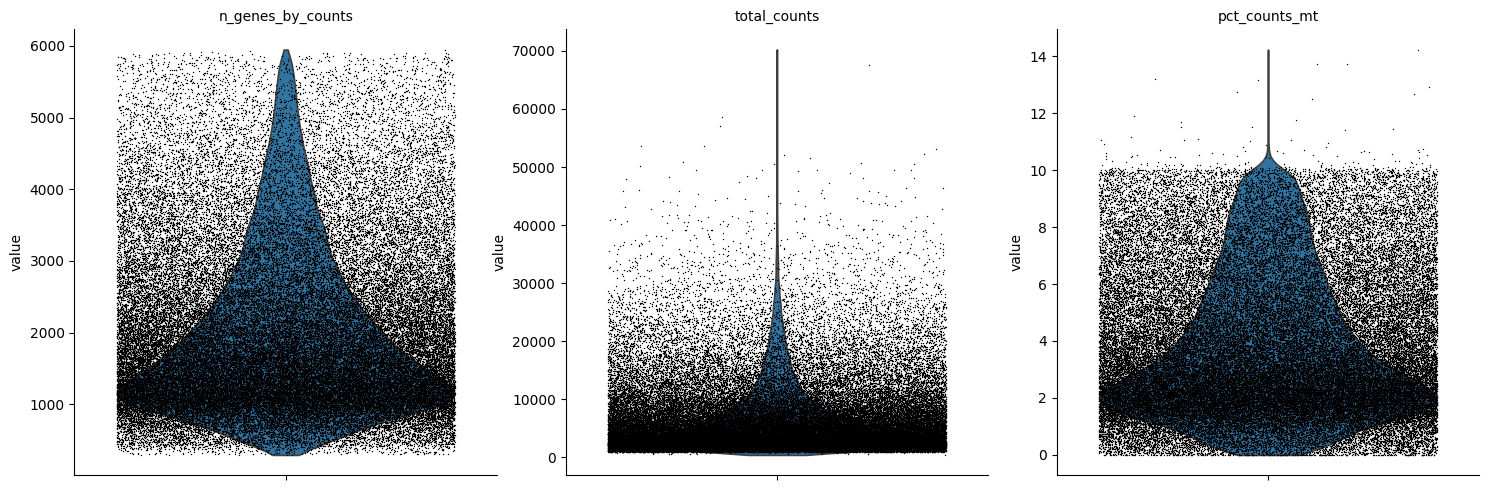

In [ ]:
import os
import scanpy as sc
import matplotlib.pyplot as plt

outdir = "./figures/"
os.makedirs(outdir, exist_ok=True)

adata.var["mt"] = adata.var_names.str.upper().str.startswith("MT-")

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    inplace=True
)

sc.pl.violin(
    adata,
    keys=[
        "n_genes_by_counts",
        "total_counts",
        "pct_counts_mt"
    ],
    jitter=0.4,
    multi_panel=True,
    show=False
)

fig = plt.gcf()

fig.savefig(
    f"{outdir}/sc_raw_QC_before_filtering.tiff",
    dpi=600,
    bbox_inches="tight",
    pil_kwargs={"compression": "tiff_lzw"}
)

fig.savefig(
    f"{outdir}/sc_raw_QC_before_filtering.svg",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# CAF

In [ ]:
adata = sc.read_h5ad("./1.rawdata/sc/CAF.h5ad")

In [ ]:
adata

AnnData object with n_obs × n_vars = 3393 × 17444
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'original_index', 'sample', 'sampleid', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90', 'leid

In [ ]:
# adata_sc = sc.read_h5ad("./1.rawdata/T.h5ad")
adata = adata_all[(adata_all.obs["celltype"] == "CAF")]
adata

View of AnnData object with n_obs × n_vars = 3816 × 17444
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'original_index', 'sample', 'sampleid', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90

In [ ]:
adata.X = adata.layers['counts'].copy()
adata.raw = adata.copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# # myeloid_adata.layers["log_norm"] = myeloid_adata.X
# cell_cycle_genes = {
#     'MCM5','PCNA','TYMS','FEN1','MCM7','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','CENPU','HELLS','RFC2',
#     'POLR1B','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1',
#     'TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','MRPL36','E2F8','HMGB2','CDK1','NUSAP1','UBE2C','BIRC5',
#     'TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','PIMREG','SMC4','CCNB2','CKAP2L','CKAP2','AURKB',
#     'BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','JPT1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5',
#     'CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA'
# }

# stress_genes = {
#     "FOS","FOSB","FOSL1","FOSL2","JUN","JUNB","JUND","ATF3",
#     "EGR1","EGR2","EGR3","EGR4",
#     "DUSP1","DUSP2","DUSP5",
#     "HSPA1A","HSPA1B","HSPH1","DNAJB1","HSP90AA1",
#     "NR4A1","NR4A2","NR4A3","IER2","IER3","BTG2","PPP1R15A","SOCS3","ZFP36","ZFP36L1","ZFP36L2",
#     "RHOB","KLF2","KLF4","GADD45A","GADD45B","GADD45G","TNFAIP3","NFKBIA","HIF1A","MYC"
# }

# var_names = pd.Index(adata.var_names.astype(str))

# mt_genes = set(var_names[var_names.str.upper().str.startswith("MT-")])
# hb_genes = set(var_names[var_names.str.upper().str.startswith("HB-")])
# ig_genes = set(var_names[var_names.str.upper().str.match(r"^IG[HKL]")])
# ribo_genes = set(var_names[
#     var_names.str.upper().str.startswith("RPS") |
#     var_names.str.upper().str.startswith("RPL")
# ])
# malat1_gene = {"MALAT1"}

# blacklist = ((cell_cycle_genes | stress_genes) &
#                  set(var_names)) | mt_genes | ribo_genes | hb_genes | ig_genes | malat1_gene

# ========= HVG =========
sc.pp.highly_variable_genes(
    adata,
    layer="counts",
    flavor="seurat_v3",
    n_top_genes=2000,
    batch_key="orig.ident"
)

# hvg_df = adata.var.loc[adata.var["highly_variable"]].copy()
# hvg_df = hvg_df.loc[~hvg_df.index.isin(blacklist)]
# final_hvgs = hvg_df.index[:2000]

# adata.var["highly_variable"] = adata.var_names.isin(final_hvgs)
adata = adata[:, adata.var.highly_variable].copy()
adata

sc.pp.regress_out(adata, ['total_counts',"pct_counts_mt"])
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack", n_comps=50)
# sc.pp.neighbors(adata, n_neighbors=20)
# Get PCs from the AnnData object
pcs = adata.obsm['X_pca']

# Run Harmony on the PCA embedding
harmony_out = hm.run_harmony(pcs,adata.obs, ["orig.ident"],max_iter_harmony= 30)

# Store corrected PCs back in the AnnData object
adata.obsm['X_pca_harmony'] = harmony_out.Z_corr

sc.pp.neighbors(adata, n_neighbors=20, n_pcs=15, use_rep="X_pca_harmony")

sc.tl.umap(adata)

2026-10-02 07:28:58,922 - harmonypy - INFO - Running Harmony
INFO:harmonypy:Running Harmony
2026-10-02 07:28:58,923 - harmonypy - INFO -   Parameters:
INFO:harmonypy:  Parameters:
2026-10-02 07:28:58,924 - harmonypy - INFO -     max_iter_harmony: 30
INFO:harmonypy:    max_iter_harmony: 30
2026-10-02 07:28:58,925 - harmonypy - INFO -     max_iter_kmeans: 4
INFO:harmonypy:    max_iter_kmeans: 4
2026-10-02 07:28:58,926 - harmonypy - INFO -     epsilon_cluster: 0.001
INFO:harmonypy:    epsilon_cluster: 0.001
2026-10-02 07:28:58,926 - harmonypy - INFO -     epsilon_harmony: 0.01
INFO:harmonypy:    epsilon_harmony: 0.01
2026-10-02 07:28:58,927 - harmonypy - INFO -     nclust: 100
INFO:harmonypy:    nclust: 100
2026-10-02 07:28:58,928 - harmonypy - INFO -     block_size: 0.05
INFO:harmonypy:    block_size: 0.05
2026-10-02 07:28:58,929 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
INFO:harmonypy:    lamb: dynamic (alpha=0.2)
2026-10-02 07:28:58,930 - harmonypy - INFO -     theta: [2. 2. 2

In [ ]:
adata = adata.raw.to_adata()
# t_adata.X = t_adata.X.astype(np.int64) ## make sure the matrix is int64
adata.raw = adata.copy()
adata.layers["counts"] = adata.X.copy()

In [ ]:
sc.pp.normalize_total(adata,target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata.copy()
adata.X = adata.layers["counts"].copy()

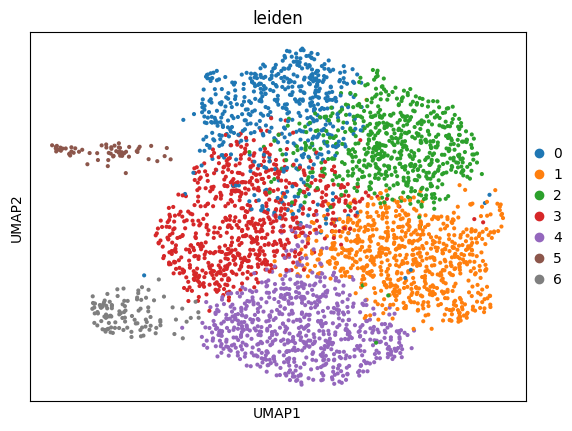

In [ ]:
sc.tl.leiden(
    adata,
    resolution=0.50,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,)
sc.pl.umap(
    adata,
    color=["leiden"],
    # legend_loc='on data'

)

In [ ]:
marker_genes_dict = {
    "T":["CD3D","CD3E","CD8A","CD8B","CD4"],
    "Treg":["FOXP3","IL2RA"],
    "NK":["FCGR3A","NCAM1",],
    "B":["CD19","CD79A","MS4A1"],
    "Plasma":['CD38',"XBP1","SDC1"],
    "Myeloid":["CD163","CD14","CD68"],
    "Epi":["KRT8","KRT18"],
    "Endo":["VWF","ENG","PECAM1"],
    "Neutrophil":["CSF3R","FCGR3B"],
    "Mast":["KIT","TPSAB1","CPA3"],
    "Fibroblast":["DCN","COL1A1","COL1A2"],
    "Pericyte":["NES","CSPG4","ABCC9"]

}



sc.pl.dotplot(adata, marker_genes_dict, 'leiden', dendrogram=False, standard_scale = "var" ,edgecolor='black',
    linewidth=0.5,)

KeyError: "Could not find keys [np.str_('CD163'), np.str_('CD19'), np.str_('CD38'), np.str_('CD4'), np.str_('CD68'), np.str_('CD8A'), np.str_('CD8B'), np.str_('CPA3'), np.str_('CSF3R'), np.str_('CSPG4'), np.str_('DCN'), np.str_('ENG'), np.str_('FCGR3A'), np.str_('FCGR3B'), np.str_('FOXP3'), np.str_('IL2RA'), np.str_('KIT'), np.str_('KRT18'), np.str_('KRT8'), np.str_('MS4A1'), np.str_('NCAM1'), np.str_('NES'), np.str_('SDC1'), np.str_('TPSAB1'), np.str_('VWF'), np.str_('XBP1')] in columns of `adata.obs` or in adata.raw.var_names."

In [ ]:
# adata = adata[
#     ~adata.obs["leiden"].isin(["6"])#"3","9","10"
# ].copy()

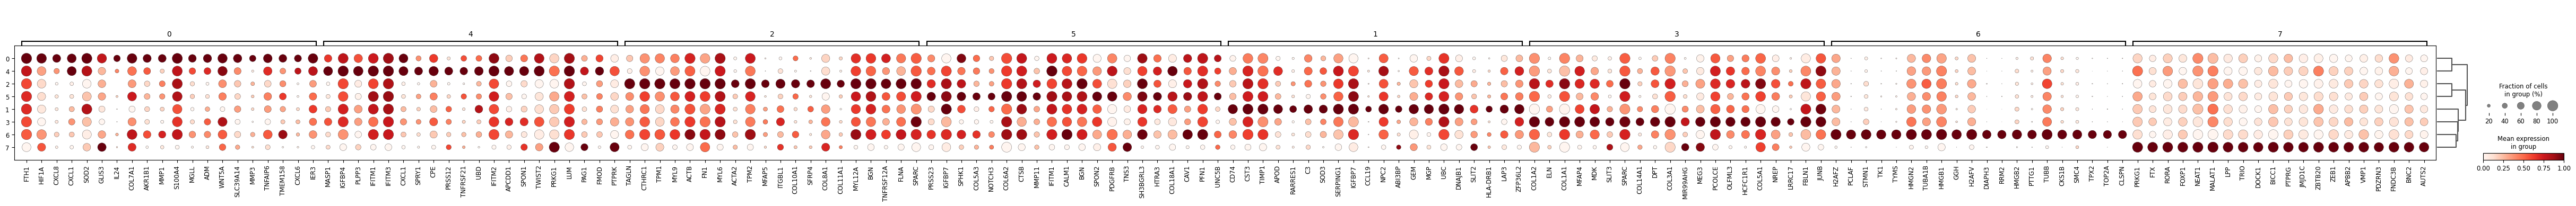

In [ ]:
grouplabel = "leiden"
sc.tl.rank_genes_groups(adata, groupby=grouplabel, method="wilcoxon",use_raw=True)
sc.tl.dendrogram(adata, groupby=grouplabel)
sc.pl.rank_genes_groups_dotplot(adata, groupby=grouplabel, standard_scale="var", n_genes=20)

In [ ]:
anno_agent(adata, cell_type = "Fibro cell in tumor", cluster_key="leiden")


'Identify cell types of Fibro cell in tumor using the following markers. Identify one cell type for each row. Attention - Determine the Subtype, Characteristic Genes, Phenotype, and Predict Function for Each Cell Type. Present the Results in a Tabular Format：\n0: FTH1,CXCL8,IL24,GAPDH,MMP1,TMEM158,S100A4,MIF,MMP3,HIF1A\n1: CD74,TIMP1,CST3,IGFBP7,APOD,LAP3,SERPING1,HLA-DRB1,RARRES1,NPC2\n2: IGFBP4,IFITM2,CXCL1,LUM,TWIST2,MASP1,CPE,IFITM3,SPON1,PLPP3\n3: BGN,FN1,CTHRC1,TPM1,TPM2,CALD1,TAGLN,ACTB,COL10A1,MYL9\n4: COL1A2,MDK,COL1A1,COL14A1,SPARC,COL3A1,MFAP4,ELN,MIR99AHG,DPT\n5: H2AFZ,TK1,PCLAF,STMN1,TUBA1B,TYMS,HMGN2,HMGB1,H2AFV,RRM2\n6: FTX,FOXP1,MALAT1,PRKG1,LPP,RORA,NEAT1,PTPRG,TRIO,ZBTB20'

In [ ]:
Identify cell types of Fibro cell in tumor using the following markers. Identify one cell type for each row. Attention - Determine the Subtype, Characteristic Genes, Phenotype, and Predict Function for Each Cell Type. Present the Results in a Tabular Format：
0: FTH1,CXCL8,IL24,GAPDH,MMP1,TMEM158,S100A4,MIF,MMP3,HIF1A
1: CD74,TIMP1,CST3,IGFBP7,APOD,LAP3,SERPING1,HLA-DRB1,RARRES1,NPC2
2: IGFBP4,IFITM2,CXCL1,LUM,TWIST2,MASP1,CPE,IFITM3,SPON1,PLPP3
3: BGN,FN1,CTHRC1,TPM1,TPM2,CALD1,TAGLN,ACTB,COL10A1,MYL9
4: COL1A2,MDK,COL1A1,COL14A1,SPARC,COL3A1,MFAP4,ELN,MIR99AHG,DPT
5: H2AFZ,TK1,PCLAF,STMN1,TUBA1B,TYMS,HMGN2,HMGB1,H2AFV,RRM2
6: FTX,FOXP1,MALAT1,PRKG1,LPP,RORA,NEAT1,PTPRG,TRIO,ZBTB20

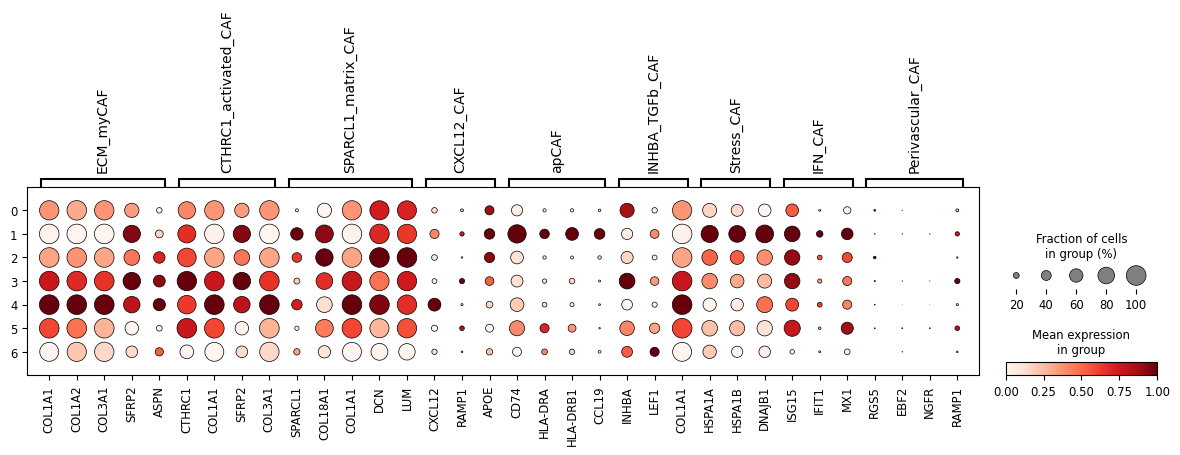

In [ ]:
CAF_marker_genes_dict = {

    "ECM_myCAF": [
        "COL1A1",
        "COL1A2",
        "COL3A1",

        "SFRP2",
        "ASPN"
    ],

    "CTHRC1_activated_CAF": [
        "CTHRC1",
        "COL1A1",
        "SFRP2",
        "COL3A1"
    ],

    "SPARCL1_matrix_CAF": [
        "SPARCL1",
        "COL18A1",
        "COL1A1",
        "DCN",
        "LUM"
    ],

    "CXCL12_CAF": [
        "CXCL12",

        "RAMP1",
        "APOE"
    ],

    "apCAF": [
        "CD74",
        "HLA-DRA",
        "HLA-DRB1",
        "CCL19"
    ],

    "INHBA_TGFb_CAF": [
        "INHBA",
        "LEF1",
        "COL1A1"
    ],

    "Stress_CAF": [
        "HSPA1A",
        "HSPA1B",
        "DNAJB1"
    ],

    "IFN_CAF": [
        "ISG15",
        "IFIT1",
        "MX1"
    ],

    "Perivascular_CAF": [
        "RGS5",
        "EBF2",
        "NGFR",
        "RAMP1",

    ]
}



sc.pl.dotplot(adata, CAF_marker_genes_dict, 'leiden', dendrogram=False, standard_scale = "var" ,edgecolor='black',
    linewidth=0.5,)

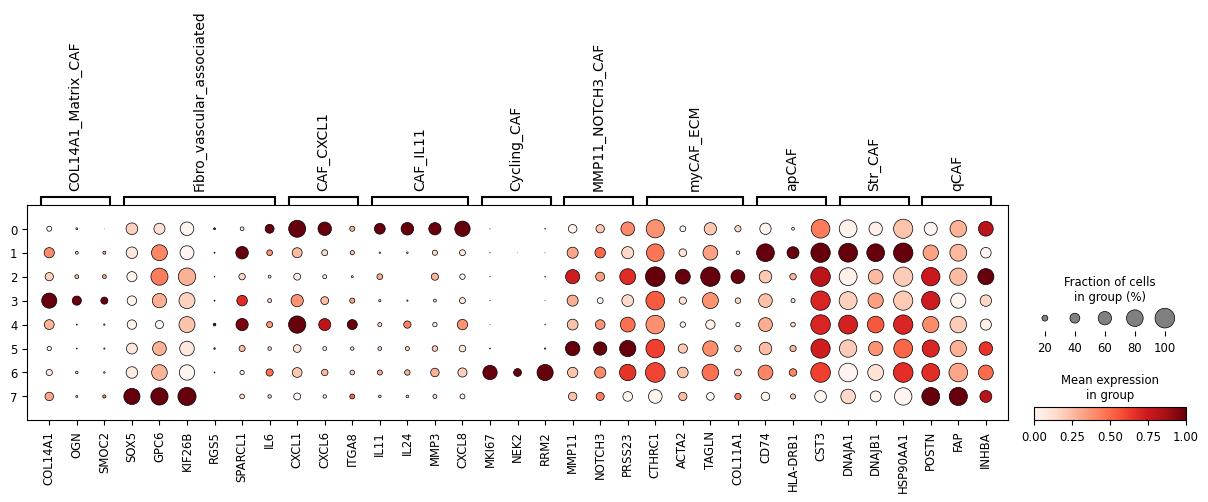

In [ ]:
marker_genes_dict = {
    "COL14A1_Matrix_CAF": [
        "COL14A1", "OGN", "SMOC2"
    ],

    "Fibro_vascular_associated": [
        "SOX5", "GPC6", "KIF26B","RGS5","SPARCL1","IL6"
    ],

    "CAF_CXCL1": [
        "CXCL1", "CXCL6", "ITGA8"
    ],

    "CAF_IL11": [
        "IL11", "IL24", "MMP3","CXCL8"
    ],

    "Cycling_CAF": [
        "MKI67", "NEK2", "RRM2"
    ],

    "MMP11_NOTCH3_CAF": [
        "MMP11", "NOTCH3", "PRSS23"
    ],

    "myCAF_ECM": [
        "CTHRC1","ACTA2", "TAGLN", "COL11A1"
    ],
    "apCAF":["CD74", "HLA-DRB1", "CST3",],
    "Str_CAF":['DNAJA1', 'DNAJB1', 'HSP90AA1',],
    "qCAF":["POSTN","FAP","INHBA",],



}
sc.pl.dotplot(
    adata,
    marker_genes_dict,
    groupby="leiden",
    dendrogram=False,
    standard_scale="var",
    edgecolor="black",
    linewidth=0.5,
)

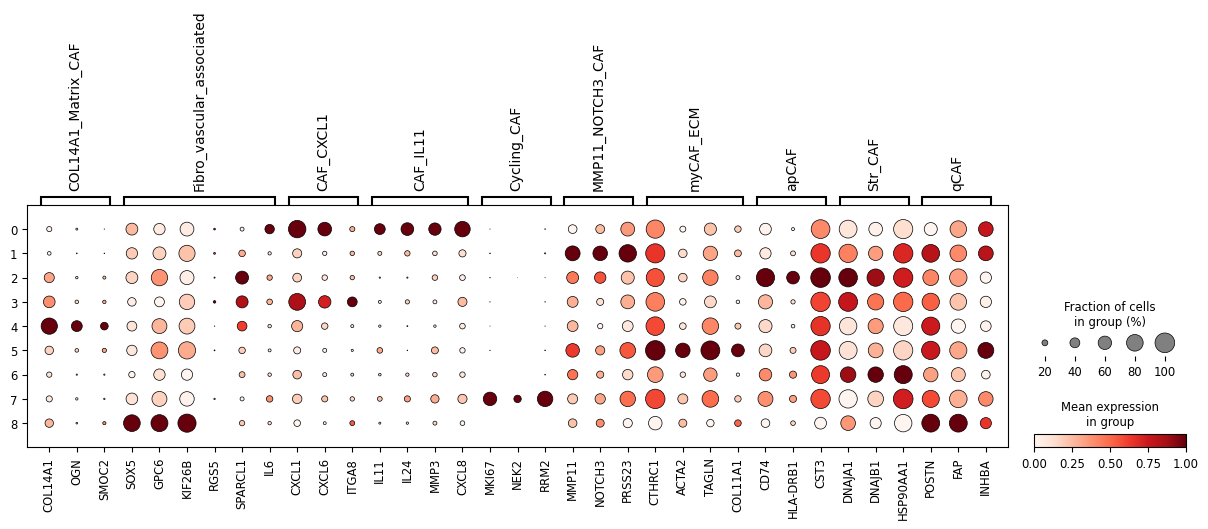

In [ ]:
marker_genes_dict = {
    "COL14A1_Matrix_CAF": [
        "COL14A1", "OGN", "SMOC2"
    ],

    "Fibro_vascular_associated": [
        "SOX5", "GPC6", "KIF26B","RGS5","SPARCL1","IL6"
    ],

    "CAF_CXCL1": [
        "CXCL1", "CXCL6", "ITGA8"
    ],

    "CAF_IL11": [
        "IL11", "IL24", "MMP3","CXCL8"
    ],

    "Cycling_CAF": [
        "MKI67", "NEK2", "RRM2"
    ],

    "MMP11_NOTCH3_CAF": [
        "MMP11", "NOTCH3", "PRSS23"
    ],

    "myCAF_ECM": [
        "CTHRC1","ACTA2", "TAGLN", "COL11A1"
    ],
    "apCAF":["CD74", "HLA-DRB1", "CST3",],
    "Str_CAF":['DNAJA1', 'DNAJB1', 'HSP90AA1',],
    "qCAF":["POSTN","FAP","INHBA",],



}
sc.pl.dotplot(
    adata,
    marker_genes_dict,
    groupby="leiden",
    dendrogram=False,
    standard_scale="var",
    edgecolor="black",
    linewidth=0.5,
)

In [ ]:
Identify cell types of Fibro cell in tumor using the following markers. Identify one cell type for each row. Attention - Determine the Subtype, Characteristic Genes, Phenotype, and Predict Function for Each Cell Type. Present the Results in a Tabular Format：
0: FTH1,CXCL8,IL24,GAPDH,MMP1,TMEM158,S100A4,MIF,MMP3,HIF1A
1: CD74,TIMP1,CST3,IGFBP7,APOD,LAP3,SERPING1,HLA-DRB1,RARRES1,NPC2
2: IGFBP4,IFITM2,CXCL1,LUM,TWIST2,MASP1,CPE,IFITM3,SPON1,PLPP3
3: BGN,FN1,CTHRC1,TPM1,TPM2,CALD1,TAGLN,ACTB,COL10A1,MYL9
4: COL1A2,MDK,COL1A1,COL14A1,SPARC,COL3A1,MFAP4,ELN,MIR99AHG,DPT
5: H2AFZ,TK1,PCLAF,STMN1,TUBA1B,TYMS,HMGN2,HMGB1,H2AFV,RRM2
6: FTX,FOXP1,MALAT1,PRKG1,LPP,RORA,NEAT1,PTPRG,TRIO,ZBTB20

In [ ]:
celltype_clusters = {
    "iCAF_CXCL8":["0"],
    "apCAF":["1"],
    'iCAF_CXCL1':['2'],
    "myCAF_CTHRC1": ["3","6"],
    "myCAF_COL14A1": ["4"],
    "Cycling_CAF":["5"],

    # "myCAF_FAP":["6"],

}

clusters = [str(c) for ids in celltype_clusters.values() for c in ids]


leiden = adata.obs["leiden"].astype(str)
adata.obs["subtype"] = "Unknown"

for celltype, cluster_ids in celltype_clusters.items():
    mask = leiden.isin([str(c) for c in cluster_ids])
    adata.obs.loc[mask, "subtype"] = celltype

adata.obs["subtype"] = adata.obs["subtype"].astype("category")

print(adata.obs["subtype"].value_counts())

print("未注释的群：",
      leiden[adata.obs["subtype"] == "Unknown"].unique().tolist())

subtype
myCAF_CTHRC1     815
apCAF            703
myCAF_COL14A1    683
iCAF_CXCL1       607
iCAF_CXCL8       524
Cycling_CAF       61
Name: count, dtype: int64
未注释的群： []


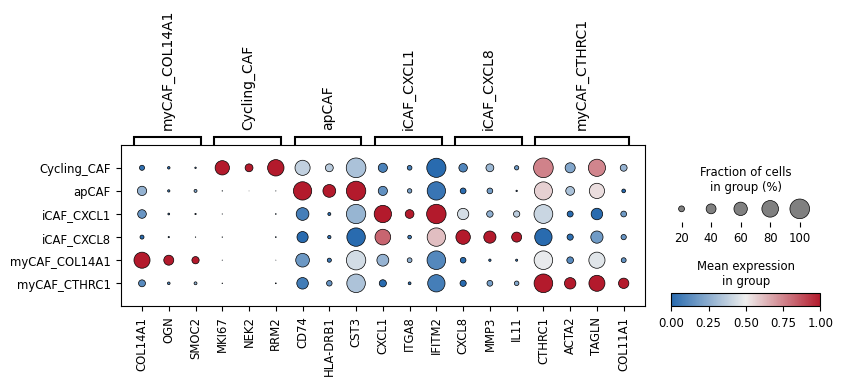

In [ ]:
marker_genes_dict = {
    "myCAF_COL14A1": [
        "COL14A1", "OGN", "SMOC2"
    ],
    "Cycling_CAF": [
        "MKI67", "NEK2", "RRM2"
    ],

    "apCAF":["CD74", "HLA-DRB1", "CST3",],
    "iCAF_CXCL1": [
        "CXCL1","ITGA8","IFITM2"
    ],
    "iCAF_CXCL8": [
        "CXCL8", "MMP3", "IL11"
    ],





    "myCAF_CTHRC1": [
        "CTHRC1","ACTA2", "TAGLN", "COL11A1"
    ],
    # "myCAF_FAP":["POSTN","FAP","SOX5",],



}
sc.pl.dotplot(
    adata,
    marker_genes_dict,
    groupby="subtype",
    dendrogram=False,
    cmap=dot_map,
    standard_scale="var",
    edgecolor="black",
    linewidth=0.5,
)

In [ ]:
adata

AnnData object with n_obs × n_vars = 3393 × 17444
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'original_index', 'sample', 'sampleid', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90', 'leid

NameError: name 'name_map' is not defined

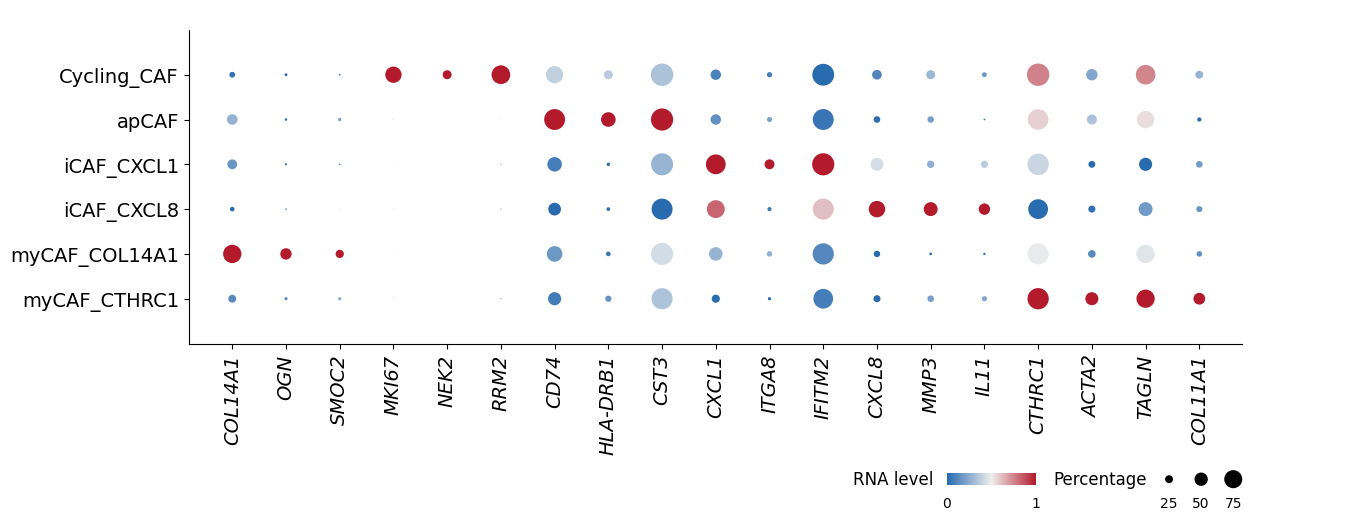

In [ ]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

genes = [
    gene
    for gene_list in marker_genes_dict.values()
    for gene in gene_list
]

DOT_SIZE = 260
SIZE_POWER = 1.5

dp = sc.pl.dotplot(
    adata,
    genes,
    groupby="subtype",
    dendrogram=False,
    cmap=dot_map,
    standard_scale="var",
    vmin=0,
    vmax=1,
    figsize=(13, 5.6),
    return_fig=True,
    show=False,
)

dp.style(
    dot_edge_color="none",
    dot_edge_lw=0,
    dot_min=0,
    dot_max=1,
    smallest_dot=0,
    largest_dot=DOT_SIZE,
    size_exponent=SIZE_POWER,
)

dp.legend(show=False)
dp.make_figure()

ax = dp.get_axes()["mainplot_ax"]
fig = ax.figure

fig.set_size_inches(13, 5.6)
fig.set_layout_engine(None)
ax.set_position([0.17, 0.36, 0.81, 0.60])

ax.tick_params(axis="x", labelsize=14, pad=4)
ax.tick_params(axis="y", labelsize=14, pad=4)

for label in ax.get_xticklabels():
    label.set_rotation(90)
    label.set_fontstyle("italic")
    label.set_ha("center")

ax.set_xlabel("")
ax.set_ylabel("")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

legend_ax = fig.add_axes([0.60, 0.065, 0.38, 0.085])
legend_ax.set_xlim(0, 1)
legend_ax.set_ylim(0, 1)
legend_ax.axis("off")

y_center = 0.62
y_label = 0.12

# 1. RNA level
legend_ax.text(
    0.00, y_center, "RNA level",
    fontsize=12, ha="left", va="center",
)

gradient = np.linspace(0, 1, 256)[None, :]
legend_ax.imshow(
    gradient,
    extent=[0.19, 0.37, 0.50, 0.74],
    cmap=dot_map,
    vmin=0,
    vmax=1,
    aspect="auto",
    origin="lower",
)

for x, label in [(0.19, "0"), (0.37, "1")]:
    legend_ax.text(
        x, y_label, label,
        fontsize=10, ha="center", va="center",
    )

# 2. Percentage
legend_ax.text(
    0.405, y_center, "Percentage",
    fontsize=12, ha="left", va="center",
)

percentages = np.array([25, 50, 75])
x_positions = [0.64, 0.705, 0.77]
legend_ax.scatter(
    x_positions,
    [y_center] * 3,
    s=DOT_SIZE * (percentages / 100) ** SIZE_POWER,
    color="black",
    edgecolors="none",
)

for x, p in zip(x_positions, percentages):
    legend_ax.text(
        x, y_label, str(p),
        fontsize=10, ha="center", va="center",
    )
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

text_right = max(
    t.get_window_extent(renderer).x1
    for t in legend_ax.texts
)

dot_center = legend_ax.transData.transform(
    (x_positions[-1], y_center)
)[0]

dot_radius = (
    np.sqrt(DOT_SIZE * (percentages[-1] / 100) ** SIZE_POWER)
    / 2 * fig.dpi / 72
)

legend_right = max(text_right, dot_center + dot_radius)

shift = (ax.get_window_extent(renderer).x1 - legend_right) / fig.bbox.width

pos = legend_ax.get_position()
legend_ax.set_position([
    pos.x0 + shift,
    pos.y0,
    pos.width,
    pos.height,
])
subtypes = adata.obs["subtype"].cat.categories
colors = adata.uns["subtype_colors"]

if len(subtypes) != len(colors):
    raise ValueError("subtype 类别数与 subtype_colors 颜色数不一致")

subtype_color_map = dict(zip(subtypes, colors))




ax.set_position([0.17, 0.36, 0.81, 0.56])
pos = ax.get_position()

top_ax = fig.add_axes([
    pos.x0,
    pos.y1 + 0.012,
    pos.width,
    0.025,
])

top_ax.set_xlim(ax.get_xlim())
top_ax.set_ylim(0, 1)
top_ax.axis("off")

ticks = ax.get_xticks()
step = ticks[1] - ticks[0] if len(ticks) > 1 else 1

start = 0
for group, gene_list in marker_genes_dict.items():
    n = len(gene_list)
    subtype = name_map.get(group, group)

    left = ticks[start] - step / 2
    width = n * step

    top_ax.add_patch(
        Rectangle(
            (left, 0),
            width,
            1,
            facecolor=subtype_color_map[subtype],
            edgecolor="none",
        )
    )
    start += n

for label in ax.get_yticklabels():
    name = label.get_text()
    if name in subtype_color_map:
        label.set_color(subtype_color_map[name])
fig.savefig(
    "./visum/figure/CAF_dotplot.tiff",
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    pil_kwargs={"compression": "tiff_lzw"},
)

plt.show()

In [ ]:
   adata.obs["subtype"].unique()

['iCAF_CXCL8', 'apCAF', 'myCAF_CTHRC1', 'myCAF_COL14A1', 'Cycling_CAF', 'iCAF_CXCL1']
Categories (6, object): ['Cycling_CAF', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_COL14A1',
                         'myCAF_CTHRC1']

In [ ]:
palette_major = [
    "#bb4055",
    "#9ec6da",
    "#e9c558",
    "#80c2ba",
    "#eba07f",
    "#a8a1c6",
    #"#a7cd70'"
]


adata.uns["subtype_colors"] = palette_major

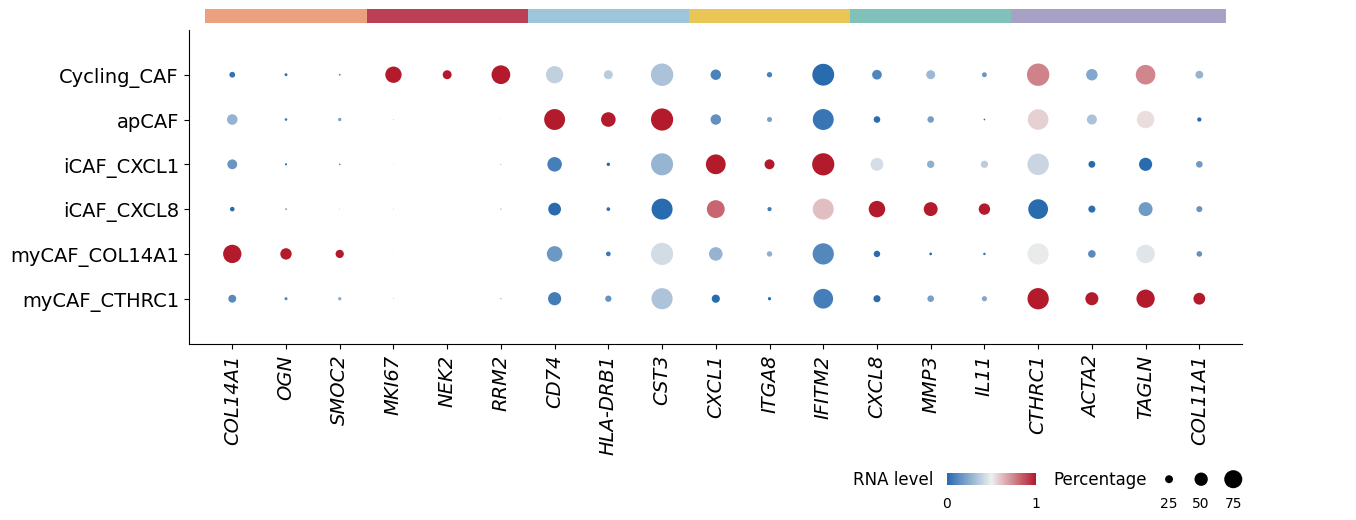

In [ ]:
fig, dp = plot_cdotplot(
    adata,
    marker_genes_dict,
    cmap=dot_map,
    groupby="subtype",
    save="./visum/figure/CAF_dotplot.tiff",
)

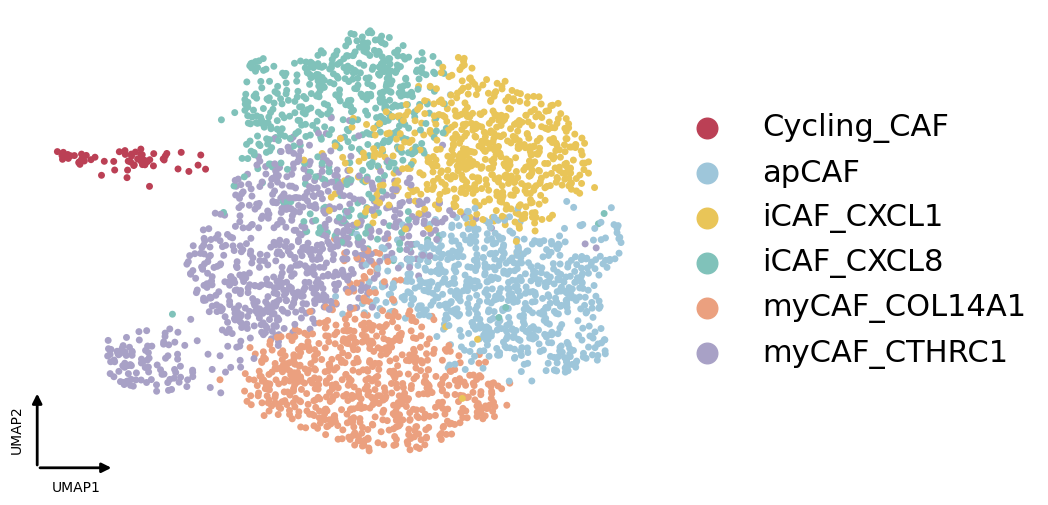

In [ ]:
fig, main_ax, arrow_ax = plot_cumap(
    adata,
    color="subtype",
    size=100,  legend_marker_size=220,

    save="./visum/figure/CAF_umap.tiff",
)

In [ ]:
adata.obs["subtype"] = adata.obs["subtype"].astype("category")
adata.obs["subtype"] = adata.obs["subtype"].cat.remove_unused_categories()

In [ ]:
adata = adata[adata.obs["subtype"] != "Unknown"].copy()

In [ ]:
adata.write_h5ad("./1.rawdata/sc/CAF.h5ad")

In [ ]:
adata_all = sc.read_h5ad("./1.rawdata/sc/Final_rebuilt_subtype.h5ad")

In [ ]:
# adata_sc.obs["subtype"] = "Unknown"

adata_all.obs["subtype"] = adata_all.obs["subtype"].astype(str)

adata_all.obs.loc[
    adata.obs_names,
    "subtype"
] = adata.obs["subtype"].values

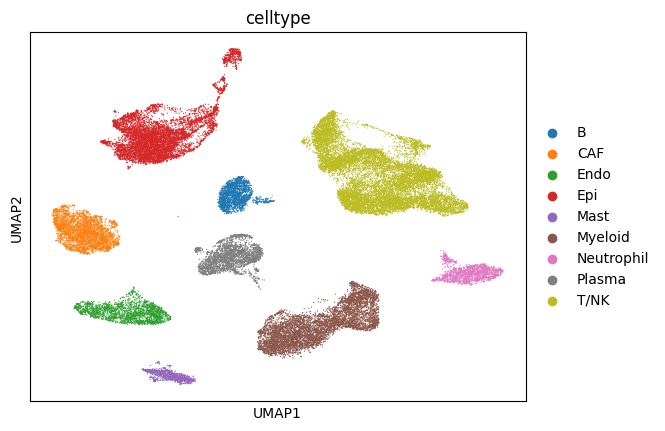

In [ ]:
sc.pl.umap(
    adata_all,
    color=["celltype"],
    # legend_loc='on data'

)

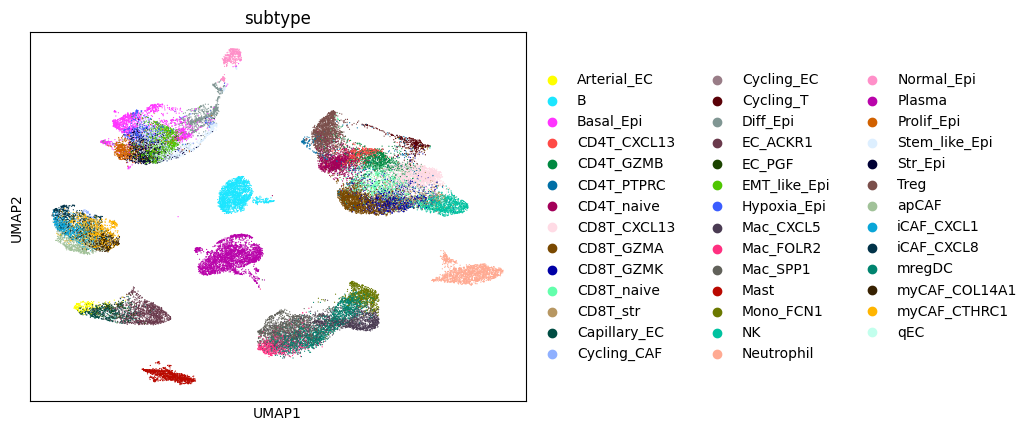

In [ ]:
sc.pl.umap(
    adata_all,
    color=["subtype"],
    # legend_loc='on data'

)

In [ ]:
adata_all.write_h5ad("./1.rawdata/sc/Final_rebuilt_subtype.h5ad")

In [ ]:
adata=sc.read_h5ad("./1.rawdata/CAF.h5ad")

In [ ]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [ ]:
adata

AnnData object with n_obs × n_vars = 3393 × 17444
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'original_index', 'sample', 'sampleid', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90', 'leid

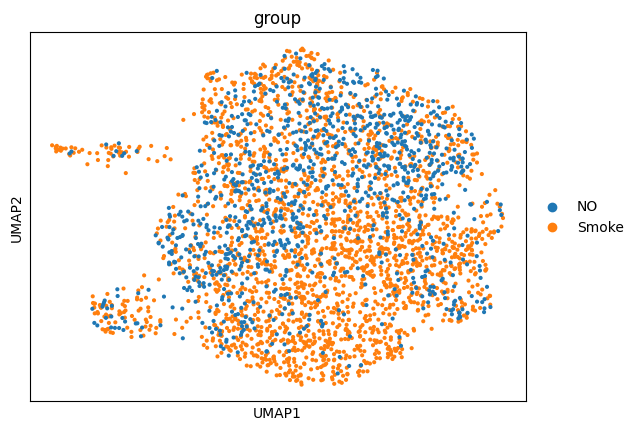

In [ ]:
sc.pl.umap(
    adata,
    color=["group"]
    # legend_loc='on data'

)

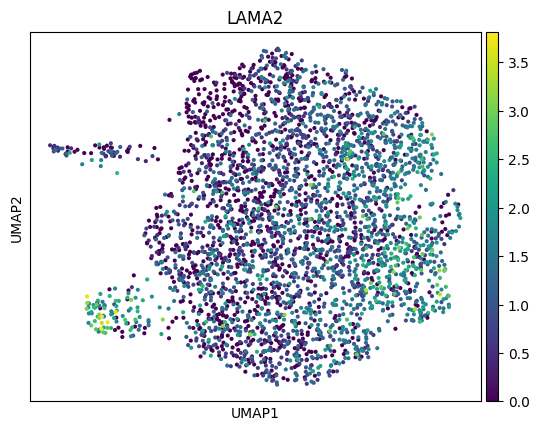

In [ ]:
sc.pl.umap(
    adata,
    color=["LAMA2"],use_raw=False
    # legend_loc='on data'

)

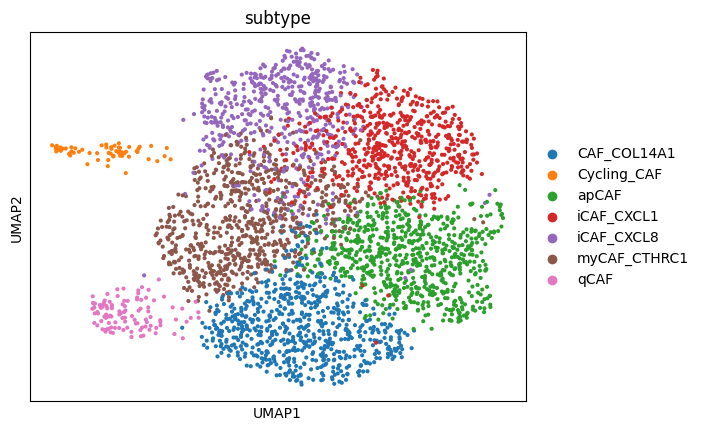

In [ ]:
sc.pl.umap(
    adata,
    color=["subtype"],
    # legend_loc='on data'

)

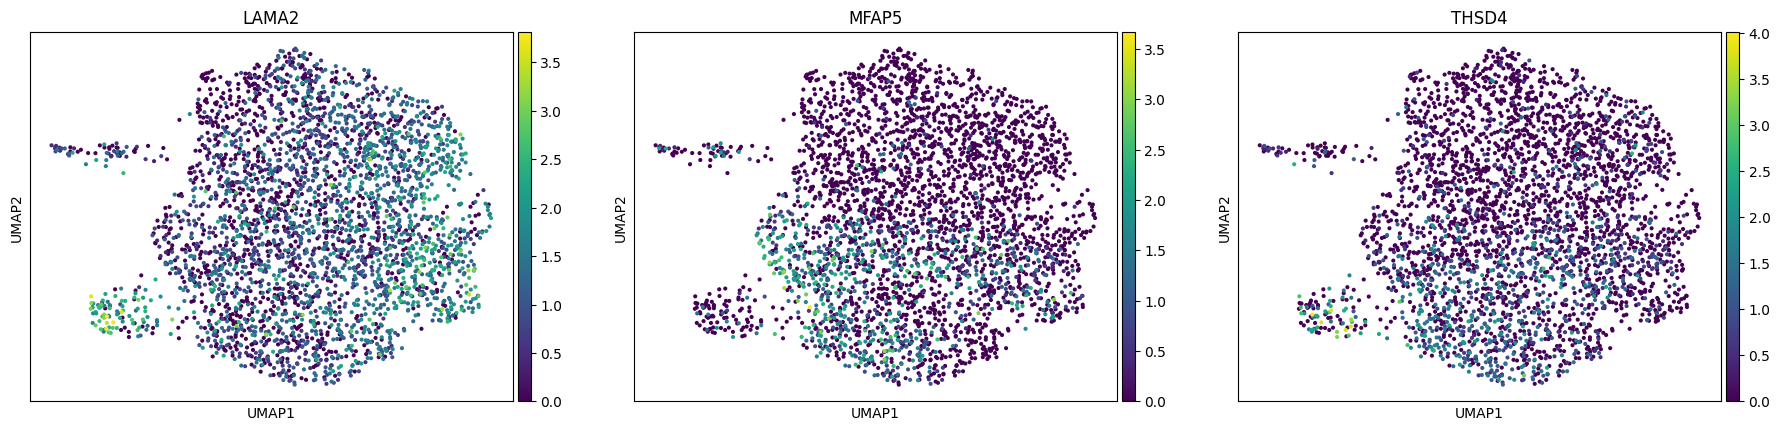

In [ ]:
sc.pl.umap(
    adata,
    color=["LAMA2","MFAP5","THSD4"],
    # legend_loc='on data'

)

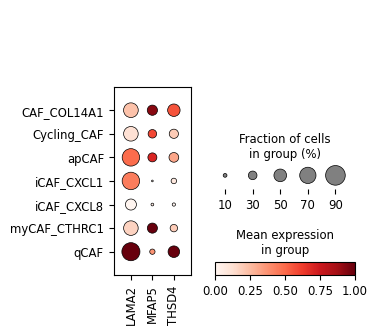

In [ ]:
marker_genes_dict = [
    "LAMA2","MFAP5","THSD4"
]
sc.pl.dotplot(
    adata,
    marker_genes_dict,
    groupby="subtype",
    dendrogram=False,
    standard_scale="var",
    edgecolor="black",
    linewidth=0.5,
)

In [ ]:
sc.tl.rank_genes_groups(adata, groupby='subtype', method="wilcoxon",use_raw=True)
sc.tl.dendrogram(adata, groupby='subtype')
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names
degs = pd.DataFrame(
    {group + '_' + key: result[key][group]
    for group in groups for key in ['names','scores', 'pvals','pvals_adj','logfoldchanges']})

In [ ]:
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names

dfs = []
for group in groups:
    df = pd.DataFrame({
        'cluster': group,
        'gene': result['names'][group],
        'log2FC': result['logfoldchanges'][group],
        'pval': result['pvals'][group],
        'pval_adj': result['pvals_adj'][group],
        'scores': result['scores'][group]
    })
    dfs.append(df)

markers = pd.concat(dfs, axis=0)

# markers.to_csv('./fibro_degene_new.csv', index=False)

In [ ]:
top200_per_cluster = markers.groupby('cluster', group_keys=False).apply(
    lambda x: x.sort_values('scores', ascending=False).head(200)
)

/tmp/ipykernel_427/3688369590.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top200_per_cluster = markers.groupby('cluster', group_keys=False).apply(


In [ ]:


res_all = []

for clu in top200_per_cluster['cluster'].unique():
    print(f'Running enrichment for {clu} ...')

    gene_list = (
        top200_per_cluster
        .loc[top200_per_cluster['cluster'] == clu, 'gene']
        .dropna()
        .unique()
        .tolist()
    )

    # #
    # if len(gene_list) < 5:
    #     print(f'Skip {clu}, too few genes')
    #     continue

    # enr = gp.enrichr(
    #     gene_list=gene_list,
    #     gene_sets='KEGG_2021_Human',
    #     organism='Human',
    #     outdir='./',
    #     cutoff=0.05
    # )

    enr = gp.enrichr(
        gene_list=gene_list,
        gene_sets='GO_Biological_Process_2025',
        organism='human',
        outdir='./',
        cutoff=0.05
    )
    # msig = gp.Msigdb()
    # gmt = msig.get_gmt(category='h.all', dbver="2025.1.Hs")
    # enr = gp.enrichr(
    # gene_list=gene_list,
    # gene_sets=gmt,
    # organism='Human',
    # outdir='./',
    # cutoff=0.05
    # )

    if enr.results is not None and enr.results.shape[0] > 0:
        df = enr.results.copy()
        df['cluster'] = clu
        res_all.append(df)

# 5. concat
enr_all = pd.concat(res_all, axis=0, ignore_index=True)


Running enrichment for CAF_COL14A1 ...
Running enrichment for Cycling_CAF ...
Running enrichment for apCAF ...
Running enrichment for iCAF_CXCL1 ...
Running enrichment for iCAF_CXCL8 ...
Running enrichment for myCAF_CTHRC1 ...
Running enrichment for qCAF ...


In [ ]:
plot_df = (
    enr_all
    .groupby('cluster', group_keys=False)
    .apply(lambda x: x.sort_values('Adjusted P-value').head(30))
)


/tmp/ipykernel_427/2566159034.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sort_values('Adjusted P-value').head(30))


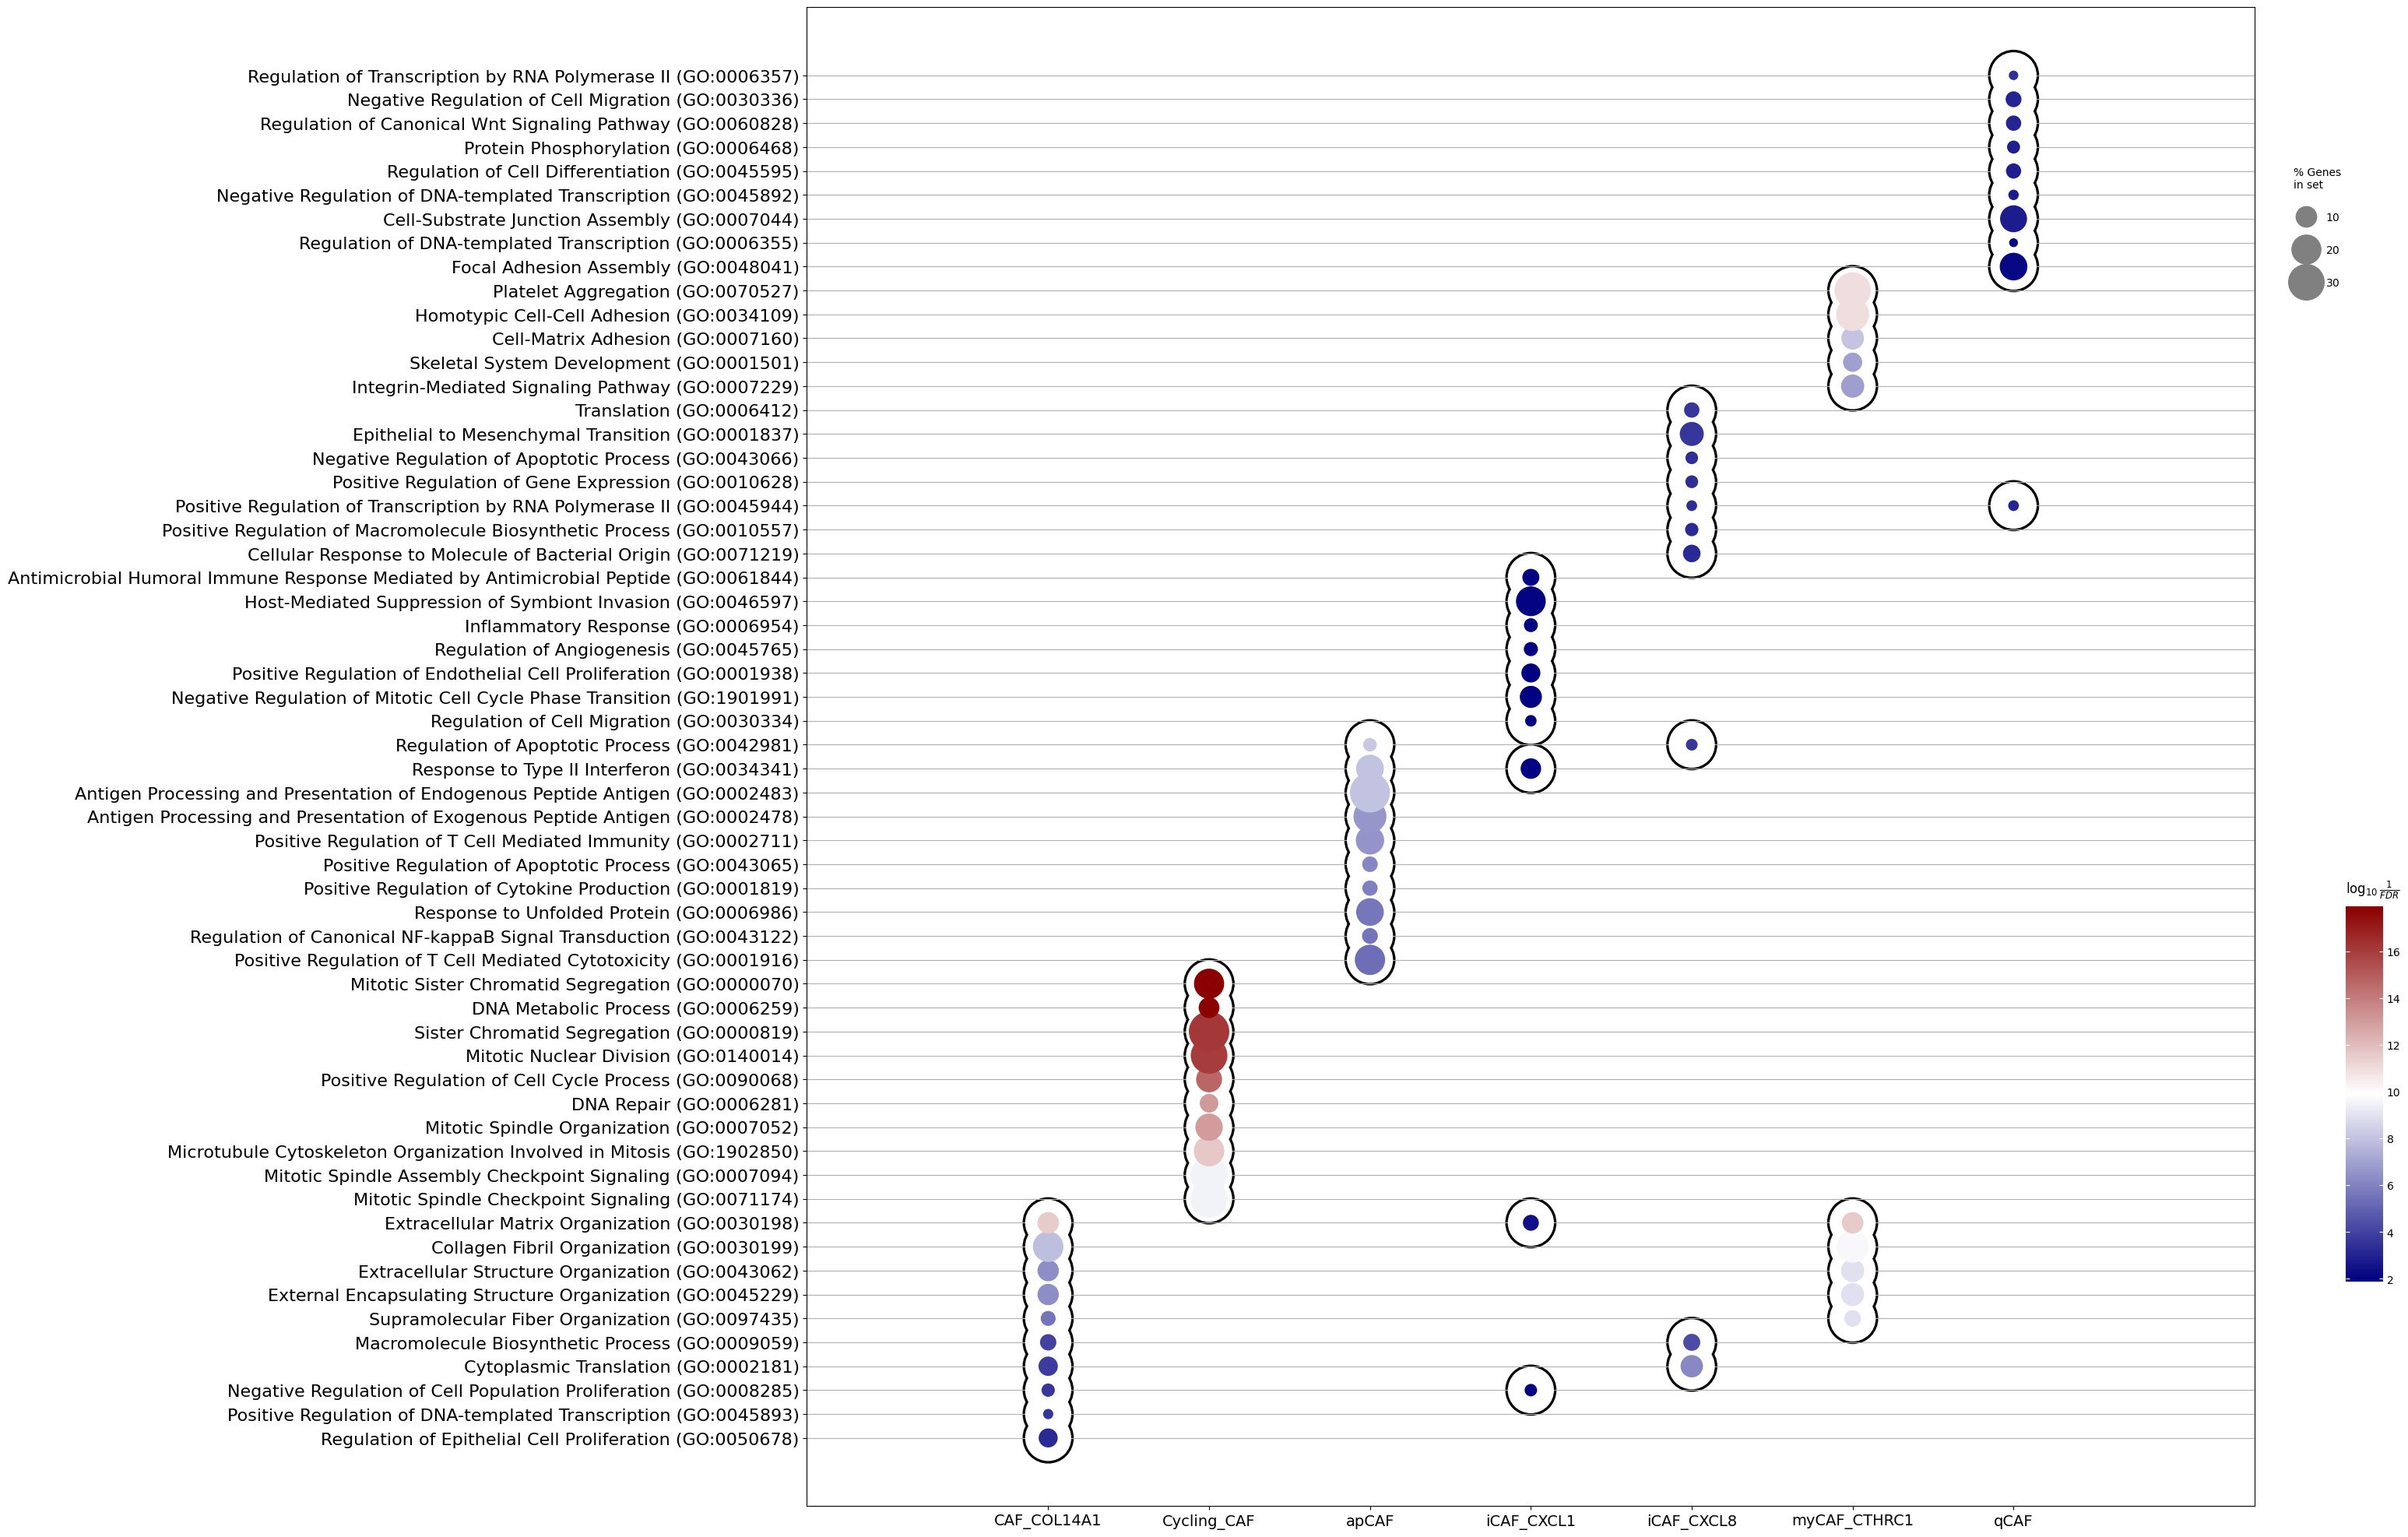

In [ ]:
from gseapy.scipalette import SciPalette
sci = SciPalette()
NbDr = sci.create_colormap()
# NbDr
ax = gp.dotplot(plot_df,figsize=(30,25),
                x='cluster',
                # x_order = ["UP","DOWN"],
                # title="GO_BP",
                cmap = NbDr,
                size=10,
                show_ring=True,
                )
ax.set_xlabel("")

fig = ax.figure
# fig.savefig("./fibro_gobp_pathway_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()

# plot

In [ ]:
adata = sc.read_h5ad("./1.rawdata/sc/Final_rebuilt_subtype.h5ad")

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt

palette_major = [
    "#bb4055", "#9ec6da", "#e9c558", "#80c2ba",
     "#eba07f", "#a8a1c6", "#a7cd70","#f2d4c0","#32769b"
]

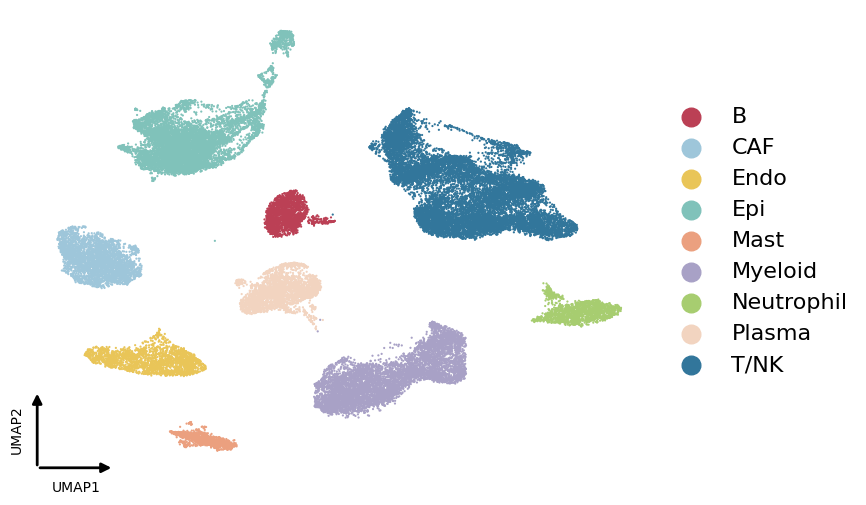

In [ ]:
fig, main_ax, arrow_ax = plot_cumap(
    adata,
    color="celltype",
    palette=palette_major,
    size=10,  legend_marker_size=180,    legend_fontsize=16,


    save="./visum/figure/celltype.tiff",
)

In [ ]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)


In [ ]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
    "niche_cmap",
    [
        "#1E2B60",
        "#28457B",
        "#2C6E88",
        "#1B9593",
        "#68B186",
        "#A2CA6E",
        "#D2DF52",
        "#F0E636",
        "#DEAC51",
        "#C5705E",
        "#A62A65",
    ],
    N=256
)

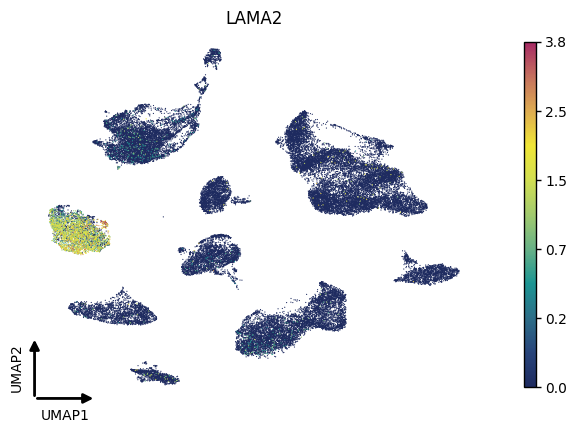

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import PowerNorm

fig, main_ax = plt.subplots()

sc.pl.umap(
    adata,
    color="LAMA2",
    cmap=cmap,
    norm=PowerNorm(gamma=0.55),
    frameon=False,
    colorbar_loc="right",
    marker=".",
    ax=main_ax,
    show=False,
)

cbar_ax = fig.axes[1]
cbar_ax.set_position([0.90, 0.14, 0.025, 0.72])
cbar_ax.tick_params(labelsize=12, width=1)
cbar = main_ax.collections[0].colorbar

ticks = cbar.norm.inverse(np.linspace(0, 1, 6))

cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{x:.1f}" for x in ticks])

cbar.ax.tick_params(labelsize=10)
for spine in cbar_ax.spines.values():
    spine.set_linewidth(1)

min_ax = fig.add_axes([0.08, 0.08, 0.22, 0.22])
min_ax.set_xlim(0, 1.2)
min_ax.set_ylim(0, 1.2)
min_ax.set_aspect("equal")
min_ax.axis("off")

x0, y0 = 0.2, 0.2
arrow_len = 0.7
x1 = x0 + arrow_len
y1 = y0 + arrow_len

min_ax.annotate(
    "",
    xy=(x1, y0),
    xytext=(x0, y0),
    arrowprops=dict(
        arrowstyle="-|>",
        lw=2,
        color="black",
        mutation_scale=14
    )
)

min_ax.annotate(
    "",
    xy=(x0, y1),
    xytext=(x0, y0),
    arrowprops=dict(
        arrowstyle="-|>",
        lw=2,
        color="black",
        mutation_scale=14
    )
)

min_ax.text(
    (x0 + x1) / 2, y0 - 0.12,
    "UMAP1",
    ha="center",
    va="top",
    fontsize=10
)

min_ax.text(
    x0 - 0.12, (y0 + y1) / 2,
    "UMAP2",
    ha="right",
    va="center",
    fontsize=10,
    rotation=90
)

fig.savefig("./visum/figure/LAMA2_umap.tiff", dpi=600, bbox_inches="tight")
plt.show()

In [ ]:
sc.pl.umap(
    adata,
    color=["celltype"],
    # legend_loc='on data'

)

In [ ]:
sc.pl.umap(
    adata,
    color=["LAMA2"],
    # legend_loc='on data'

)

In [ ]:
adata=sc.read_h5ad("./1.rawdata/CAF.h5ad")

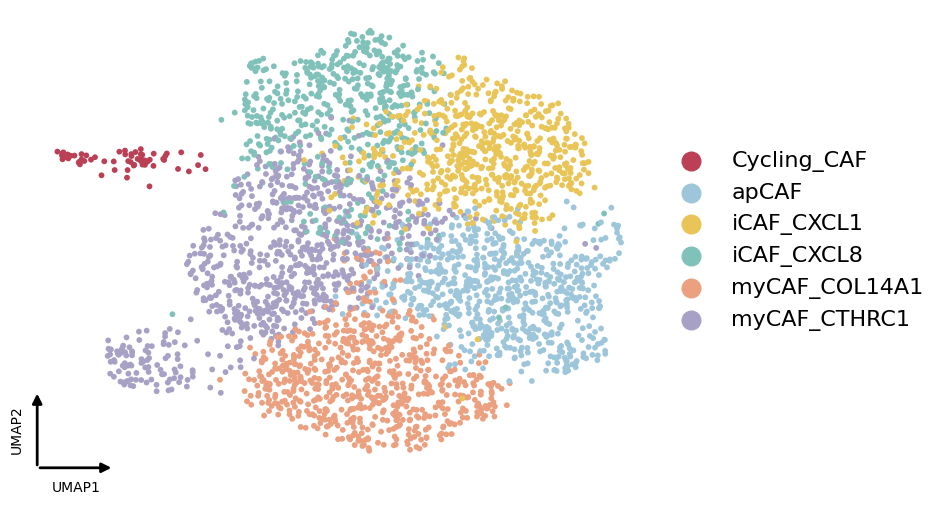

In [ ]:
# palette_major = [
#     "#bb4055", "#9ec6da", "#e9c558", "#80c2ba",
#     "#eba07f", "#a8a1c6", "#a7cd70", "#f2d4c0", "#32769b",
# ]

fig, main_ax, arrow_ax = plot_cumap(
    adata,
    color="subtype",
    # palette=palette_major,
    size=70, legend_marker_size=180, legend_fontsize=16,
    save="./visum/figure/CAF_subtype.tiff",
)

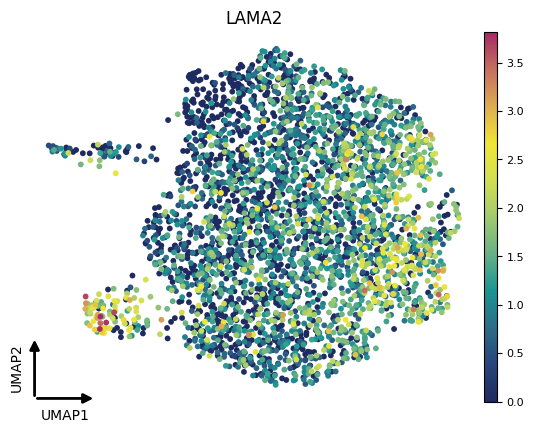

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt


fig, main_ax = plt.subplots()

sc.pl.umap(
    adata,
    color="LAMA2",
    cmap=cmap,
    frameon=False,
    colorbar_loc="right",
    marker=".",
    ax=main_ax,
    show=False,size=70
)

min_ax = fig.add_axes([0.08, 0.08, 0.22, 0.22])
min_ax.set_xlim(0, 1.2)
min_ax.set_ylim(0, 1.2)
min_ax.set_aspect("equal")
min_ax.axis("off")

x0, y0 = 0.2, 0.2
arrow_len = 0.7

x1 = x0 + arrow_len
y1 = y0 + arrow_len

min_ax.annotate(
    "",
    xy=(x1, y0),
    xytext=(x0, y0),
    arrowprops=dict(
        arrowstyle="-|>",
        lw=2,
        color="black",
        mutation_scale=14
    )
)

min_ax.annotate(
    "",
    xy=(x0, y1),
    xytext=(x0, y0),
    arrowprops=dict(
        arrowstyle="-|>",
        lw=2,
        color="black",
        mutation_scale=14
    )
)

min_ax.text(
    (x0 + x1) / 2, y0 - 0.12,
    "UMAP1",
    ha="center",
    va="top",
    fontsize=10
)

min_ax.text(
    x0 - 0.12, (y0 + y1) / 2,
    "UMAP2",
    ha="right",
    va="center",
    fontsize=10,
    rotation=90
)
for ax in fig.axes:
    if ax != main_ax:
        ax.tick_params(
            labelsize=8,
            width=0.8
        )
# fig.savefig("B_P_subtype_umap.pdf", bbox_inches="tight")
fig.savefig("./visum/figure/CAF_LAMA2_umap.tiff", dpi=600, bbox_inches="tight")
plt.show()

               mean_expression  percent_expressed  n_cells
subtype                                                   
Cycling_CAF           1.983607          60.655738       61
apCAF                 3.522048          76.813656      703
iCAF_CXCL1            2.812191          77.100494      607
iCAF_CXCL8            1.003817          41.793893      524
myCAF_COL14A1         1.824305          61.200586      683
myCAF_CTHRC1          1.932515          63.067485      815


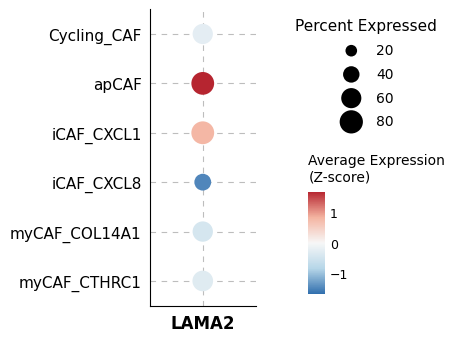

In [ ]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

GENE = "LAMA2"
GROUP = "subtype"

USE_RAW = False          # False：adata.X；True：adata.raw.X
LAYER = None

ZSCORE = True
ORDER = None

MAX_DOT_SIZE = 350
LEGEND_PCTS = [20, 40, 60, 80]

OUTFILE = "./visum/figure/LAMA2_subtype_dotplot.tiff"

cmap = LinearSegmentedColormap.from_list(
    "dot_map",
    ["#306EAD", "#B6D6E8", "#F7F7F7", "#F4B4A1", "#B62530"],
)

if USE_RAW and LAYER is not None:
    raise ValueError("USE_RAW=True 时，请将 LAYER 设为 None")

df = sc.get.obs_df(
    adata,
    keys=[GROUP, GENE],
    use_raw=USE_RAW,
    layer=LAYER,
)

df = df.dropna(subset=[GROUP, GENE]).copy()
df = df.loc[np.isfinite(df[GENE])].copy()

if df.empty:
    raise ValueError("没有可用于绘图的有效数据")

if (df[GENE] < 0).any():
    raise ValueError(
        "表达中存在负值，请选择未经 scale 的 log 标准化表达矩阵，"
        "以便用 LAMA2 > 0 计算阳性比例。"
    )

df["positive"] = df[GENE] > 0

summary = df.groupby(GROUP, observed=True).agg(
    mean_expression=(GENE, "mean"),
    percent_expressed=("positive", "mean"),
    n_cells=(GENE, "size"),
)

summary["percent_expressed"] *= 100

if ORDER is not None:
    missing = [x for x in ORDER if x not in summary.index]
    if missing:
        raise ValueError(f"以下亚型不存在或没有有效细胞：{missing}")
    summary = summary.loc[ORDER].copy()

means = summary["mean_expression"]

if ZSCORE:
    sd = means.std(ddof=0)
    summary["color_value"] = (
        (means - means.mean()) / sd
        if sd > 0 else np.zeros(len(means))
    )

    limit = max(float(summary["color_value"].abs().max()), 1e-6)
    vmin, vmax = -limit, limit
    color_title = "Average Expression\n(Z-score)"
else:
    summary["color_value"] = means
    vmin = 0
    vmax = max(float(means.max()), 1e-6)
    color_title = "Average Expression"

print(summary[["mean_expression", "percent_expressed", "n_cells"]])

n = len(summary)
y = np.arange(n)

fig = plt.figure(figsize=(4.8, max(3.8, n * 0.48)))

ax = fig.add_axes([0.42, 0.15, 0.22, 0.78])
size_ax = fig.add_axes([0.71, 0.58, 0.27, 0.34])
cax = fig.add_axes([0.75, 0.18, 0.035, 0.27])
size_ax.axis("off")

for yi in y:
    ax.axhline(
        yi,
        color="#BDBDBD",
        linewidth=0.8,
        linestyle=(0, (5, 5)),
        zorder=0,
    )

ax.axvline(
    0,
    color="#BDBDBD",
    linewidth=0.8,
    linestyle=(0, (5, 5)),
    zorder=0,
)

dots = ax.scatter(
    np.zeros(n),
    y,
    s=summary["percent_expressed"].to_numpy() / 100 * MAX_DOT_SIZE,
    c=summary["color_value"].to_numpy(),
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    edgecolors="none",
    zorder=3,
)

ax.set_yticks(y)
ax.set_yticklabels(summary.index.astype(str), fontsize=11)
ax.set_xticks([0])
ax.set_xticklabels([GENE], fontsize=12, fontweight="bold")

ax.set_xlim(-0.55, 0.55)
ax.set_ylim(n - 0.5, -0.5)
ax.tick_params(axis="both", length=0, pad=6)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

handles = [
    ax.scatter(
        [], [],
        s=p / 100 * MAX_DOT_SIZE,
        color="black",
        edgecolors="none",
        label=str(p),
    )
    for p in LEGEND_PCTS
]

size_ax.legend(
    handles=handles,
    title="Percent Expressed",
    loc="upper left",
    frameon=False,
    fontsize=10,
    title_fontsize=11,
    labelspacing=0.7,
    handletextpad=0.8,
    borderaxespad=0,
)

cbar = fig.colorbar(dots, cax=cax)
cbar.ax.set_title(color_title, fontsize=10, loc="left", pad=8)
cbar.ax.tick_params(labelsize=9, length=0)
cbar.outline.set_visible(False)

out = Path(OUTFILE)
out.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    out,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    pil_kwargs={"compression": "tiff_lzw"},
)

plt.show()

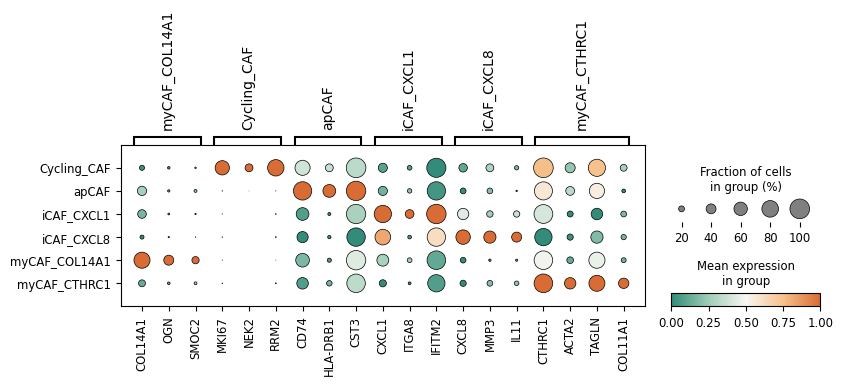

In [ ]:
marker_genes_dict = {
    "myCAF_COL14A1": [
        "COL14A1", "OGN", "SMOC2"
    ],
    "Cycling_CAF": [
        "MKI67", "NEK2", "RRM2"
    ],

    "apCAF":["CD74", "HLA-DRB1", "CST3",],
    "iCAF_CXCL1": [
        "CXCL1","ITGA8","IFITM2"
    ],
    "iCAF_CXCL8": [
        "CXCL8", "MMP3", "IL11"
    ],





    "myCAF_CTHRC1": [
        "CTHRC1","ACTA2", "TAGLN", "COL11A1"
    ],
    # "myCAF_FAP":["POSTN","FAP","SOX5",],



}
sc.pl.dotplot(
    adata,
    marker_genes_dict,
    groupby="subtype",
    dendrogram=False,
    cmap=dot_map,
    standard_scale="var",
    edgecolor="black",
    linewidth=0.5,
)

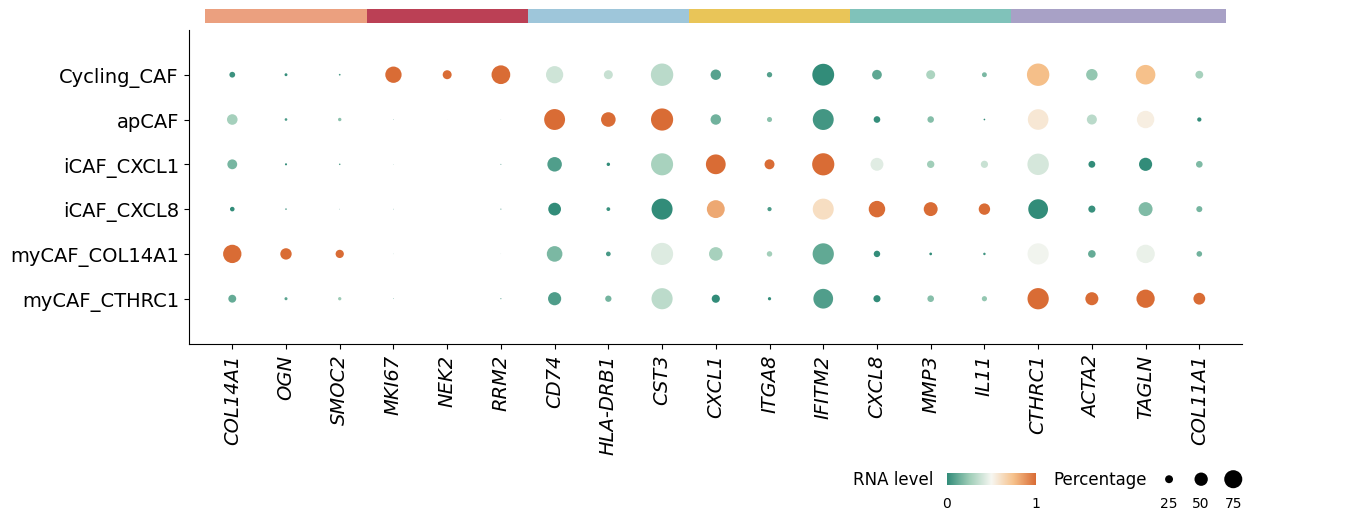

In [ ]:
# fig, main_ax, arrow_ax = plot_cdotplot(
#     adata,
#     size=10,  #legend_marker_size=70,

#     save="./visum/figure/caf_cotplot.tiff",
# )

fig, dp = plot_cdotplot(
    adata,
    marker_genes_dict,
    cmap=dot_map,show_subtype=True,
    groupby="subtype",

    save="./visum/figure/caf_cotplot.tiff",
)

In [ ]:
adata_all.write_h5ad("./1.rawdata/Final_rebuilt.h5ad")

In [ ]:
adata= sc.read_h5ad("./1.rawdata/CAF.h5ad")

In [ ]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

   sampleid  group     LAMA2
0      NO_1     NO  0.945177
1      NO_1  Smoke       NaN
2      NO_2     NO  1.013061
3      NO_2  Smoke       NaN
4      NO_3     NO  0.501362
5      NO_3  Smoke       NaN
6   Smoke_1     NO       NaN
7   Smoke_1  Smoke  1.030401
8   Smoke_2     NO       NaN
9   Smoke_2  Smoke  0.784409
10  Smoke_3     NO       NaN
11  Smoke_3  Smoke  0.664586
p value: nan


/tmp/ipykernel_8115/1107681614.py:43: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["sampleid", "group"])


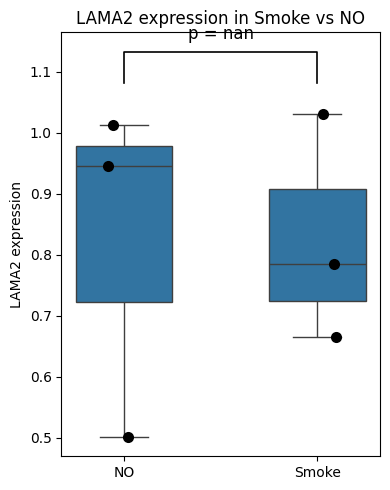

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu


#==============================
#==============================

gene = "LAMA2"

if gene in adata.var_names:
    expr = adata[:, gene].X
    if hasattr(expr, "toarray"):
        expr = expr.toarray()
    expr = expr.flatten()

    df = pd.DataFrame({
        "LAMA2": expr,
        "group": adata.obs["group"].values,
        "sampleid": adata.obs["sampleid"].values
    })

else:
    df = pd.DataFrame({
        "LAMA2": adata.obs[gene],
        "group": adata.obs["group"],
        "sampleid": adata.obs["sampleid"]
    })


#==============================
#==============================

sample_df = (
    df
    .groupby(["sampleid", "group"])
    ["LAMA2"]
    .mean()
    .reset_index()
)


print(sample_df)


#==============================
#==============================

smoke = sample_df.loc[
    sample_df.group=="Smoke",
    "LAMA2"
]

no = sample_df.loc[
    sample_df.group=="NO",
    "LAMA2"
]


stat, p = mannwhitneyu(
    smoke,
    no,
    alternative="two-sided"
)

print("p value:", p)


#==============================
#==============================

plt.figure(figsize=(4,5))


ax = sns.boxplot(
    data=sample_df,
    x="group",
    y="LAMA2",
    width=0.5,
    showfliers=False
)


sns.stripplot(
    data=sample_df,
    x="group",
    y="LAMA2",
    size=8,
    color="black",
    jitter=True
)


ymax = sample_df["LAMA2"].max()

plt.plot(
    [0,0,1,1],
    [
        ymax*1.05,
        ymax*1.10,
        ymax*1.10,
        ymax*1.05
    ],
    lw=1.2,
    color="black"
)


plt.text(
    0.5,
    ymax*1.12,
    f"p = {p:.3f}",
    ha="center",
    fontsize=12
)


plt.xlabel("")
plt.ylabel("LAMA2 expression")

plt.title(
    "LAMA2 expression in Smoke vs NO"
)

plt.tight_layout()

plt.show()

# plot

In [31]:
adata_all = sc.read_h5ad("./1.rawdata/sc/Final_rebuilt_subtype.h5ad")

In [33]:
palette_major = [
    "#d6e7a3",
    "#f58d93",
    "#f7a7a8",
    "#6c9cc4",
    "#ccc9e6",
    "#ffd121",
    "#bdbdbd",
    "#4aad44",
    "#57c3f3"

]

palette_major = [
    "#bb4055", "#9ec6da", "#e9c558", "#80c2ba",
     "#eba07f", "#a8a1c6", "#a7cd70","#f2d4c0","#32769b"
]
adata_all.uns["celltype_colors"] = palette_major

In [27]:
# adata_all.obs["celltype"] = adata_all.obs["celltype"].replace({"T/NK": "T"})

/tmp/ipykernel_1345/2435008220.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  adata_all.obs["celltype"] = adata_all.obs["celltype"].replace({"T/NK": "T"})


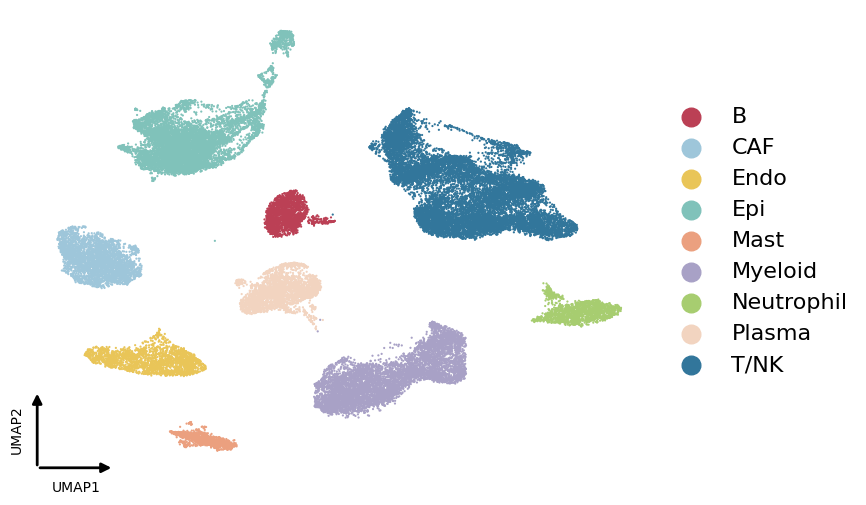

In [34]:
fig, main_ax, arrow_ax = plot_cumap(
    adata_all,
    color="celltype",
    size=10,  legend_marker_size=180,legend_fontsize=16,

    save="./visum/figure/atlas_umap_clltype.tiff",
)

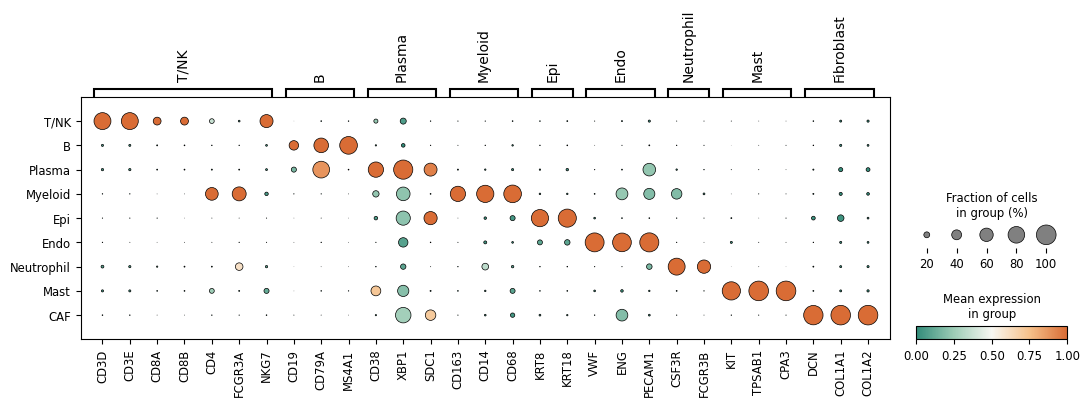

In [38]:
marker_genes_dict = {
    "T/NK":["CD3D","CD3E","CD8A","CD8B","CD4","FCGR3A","NKG7"],
    # "Treg":["FOXP3","IL2RA"],
    # "NK":["FCGR3A","NCAM1",],
    "B":["CD19","CD79A","MS4A1"],
    "Plasma":['CD38',"XBP1","SDC1"],
    "Myeloid":["CD163","CD14","CD68"],
    "Epi":["KRT8","KRT18"],
    "Endo":["VWF","ENG","PECAM1"],
    "Neutrophil":["CSF3R","FCGR3B"],
    "Mast":["KIT","TPSAB1","CPA3"],
    "Fibroblast":["DCN","COL1A1","COL1A2"],
    # "Pericyte":["NES","CSPG4","ABCC9"],
    # "gdT":["TRDC"]

}

dot_map = LinearSegmentedColormap.from_list(
    "dot_map",
    [
        "#328C79",
        "#9ECDB7",
        "#F7F7F2",
        "#F6C18B",
        "#D96C35",
    ],
    N=256
)
celltype_order = [
    "T/NK",
    "B",
    "Plasma",
    "Myeloid",
    "Epi",
    "Endo",
    "Neutrophil",
    "Mast",
    "CAF",
]

dp = sc.pl.dotplot(
    adata_all,
    marker_genes_dict,
    groupby="celltype",
    categories_order=celltype_order,
    dendrogram=False,
    cmap=dot_map,
    standard_scale="var",
    edgecolor="black",
    linewidth=0.5,
    return_fig=True,
)

dp.savefig(
    "./visum/figure/marker_dotplot.tiff",
    dpi=600,
    bbox_inches="tight",
    pil_kwargs={"compression": "tiff_lzw"},
)



In [ ]:
marker_genes_dict = {
    "T/NK":["CD3D","CD3E","CD8A","CD8B","CD4"],
    # "Treg":["FOXP3","IL2RA"],
    # "NK":["FCGR3A","NCAM1",],
    "B":["CD19","CD79A","MS4A1"],
    "Plasma":['CD38',"XBP1","SDC1"],
    "Myeloid":["CD163","CD14","CD68"],
    "Epi":["KRT8","KRT18"],
    "Endo":["VWF","ENG","PECAM1"],
    "Neutrophil":["CSF3R","FCGR3B"],
    "Mast":["KIT","TPSAB1","CPA3"],
    "Fibroblast":["DCN","COL1A1","COL1A2"],
    # "Pericyte":["NES","CSPG4","ABCC9"],
    # "gdT":["TRDC"]

}
celltype_order = [
    "T/NK",
    "B",
    "Plasma",
    "Myeloid",
    "Epi",
    "Endo",
    "Neutrophil",
    "Mast",
    "CAF",
]

dp = sc.pl.dotplot(
    adata_all,
    marker_genes_dict,
    groupby="celltype",
    categories_order=celltype_order,
    dendrogram=False,
    cmap=dot_map,
    standard_scale="var",
    edgecolor="black",
    linewidth=0.5,
    return_fig=True,
)

dp.savefig(
    "./visum/figure/marker_dotplot.tiff",
    dpi=600,
    bbox_inches="tight",
    pil_kwargs={"compression": "tiff_lzw"},
)



In [ ]:
adata_all

AnnData object with n_obs × n_vars = 40980 × 13879
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'original_index', 'sample', 'sampleid', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90', 'lei

In [ ]:
palette_major = [
    '#306ead',
    "#b62530"

]


adata_all.uns["group_colors"] = palette_major

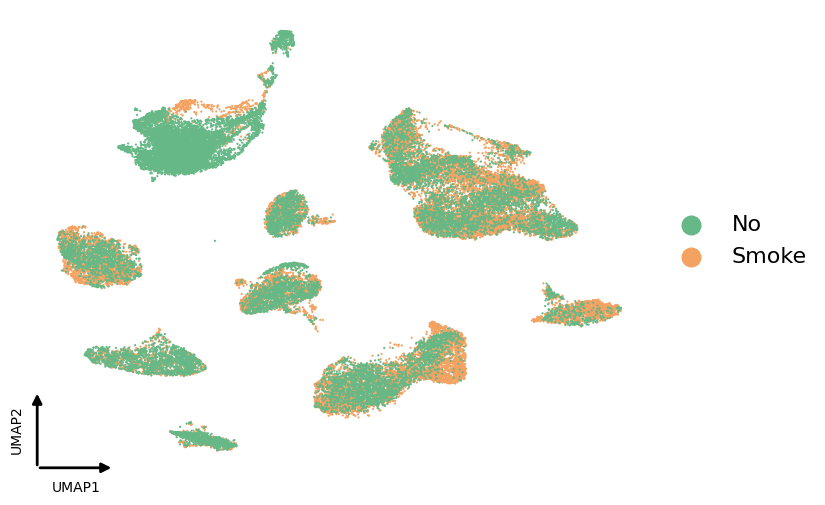

In [ ]:
adata_all.obs["group"] = (
    adata_all.obs["group"]
    .astype(str)
    .replace({"NO": "No"})
)

palette_major = {
    "No": "#66B887",
    "Smoke": "#F4A261",
}

fig, main_ax, arrow_ax = plot_cumap(
    adata_all,
    color="group",
    palette=palette_major,
    size=10,
    legend_marker_size=180, legend_fontsize=16,
    save="./visum/figure/atlas_umap_group.tiff",
)

In [ ]:
patient_colors = {
    "No_1":    "#4C78A8",
    "No_2":    "#72B7B2",
    "No_3":    "#A6CEE3",

    "Smoke_1": "#B94A48",
    "Smoke_2": "#DD8452",
    "Smoke_3": "#E8A5A5",
}

palette_patient = [
    patient_colors[x]
    for x in adata_all.obs["orig.ident"].cat.categories
]

adata_all.uns["orig.ident_colors"] = palette_patient


KeyError: 'NO_1'

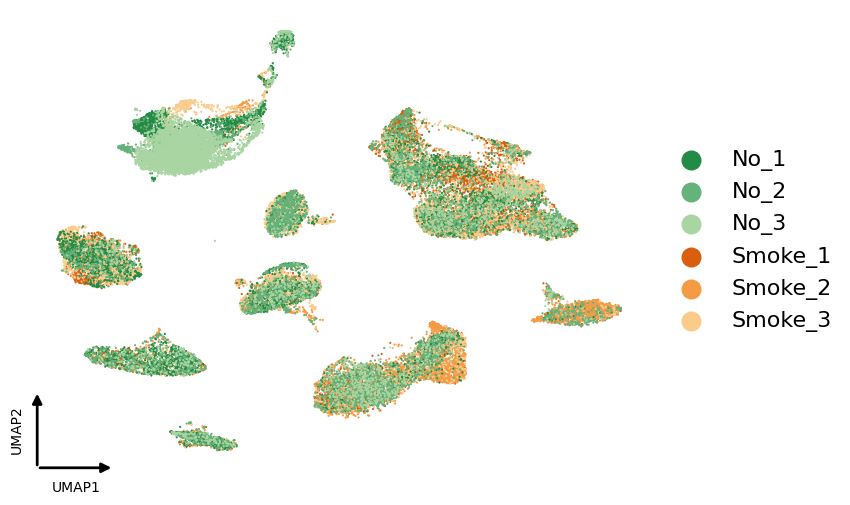

In [ ]:
adata_all.obs["orig.ident"] = adata_all.obs["orig.ident"].replace({
    "NO_1": "No_1",
    "NO_2": "No_2",
    "NO_3": "No_3",
})
patient_colors = {
    "No_1":    "#238B45",
    "No_2":    "#66B27B",
    "No_3":    "#A8D5A2",

    "Smoke_1": "#D95F0E",
    "Smoke_2": "#F59B45",
    "Smoke_3": "#FBCB8B",
}
palette_patient = [
    patient_colors[x]
    for x in adata_all.obs["orig.ident"].cat.categories
]

adata_all.uns["orig.ident_colors"] = palette_patient
fig, main_ax, arrow_ax = plot_cumap(
    adata_all,
    color="orig.ident",
    size=10,  legend_marker_size=180,legend_fontsize=16,

    save="./visum/figure/atlas_umap_patient.tiff",
)

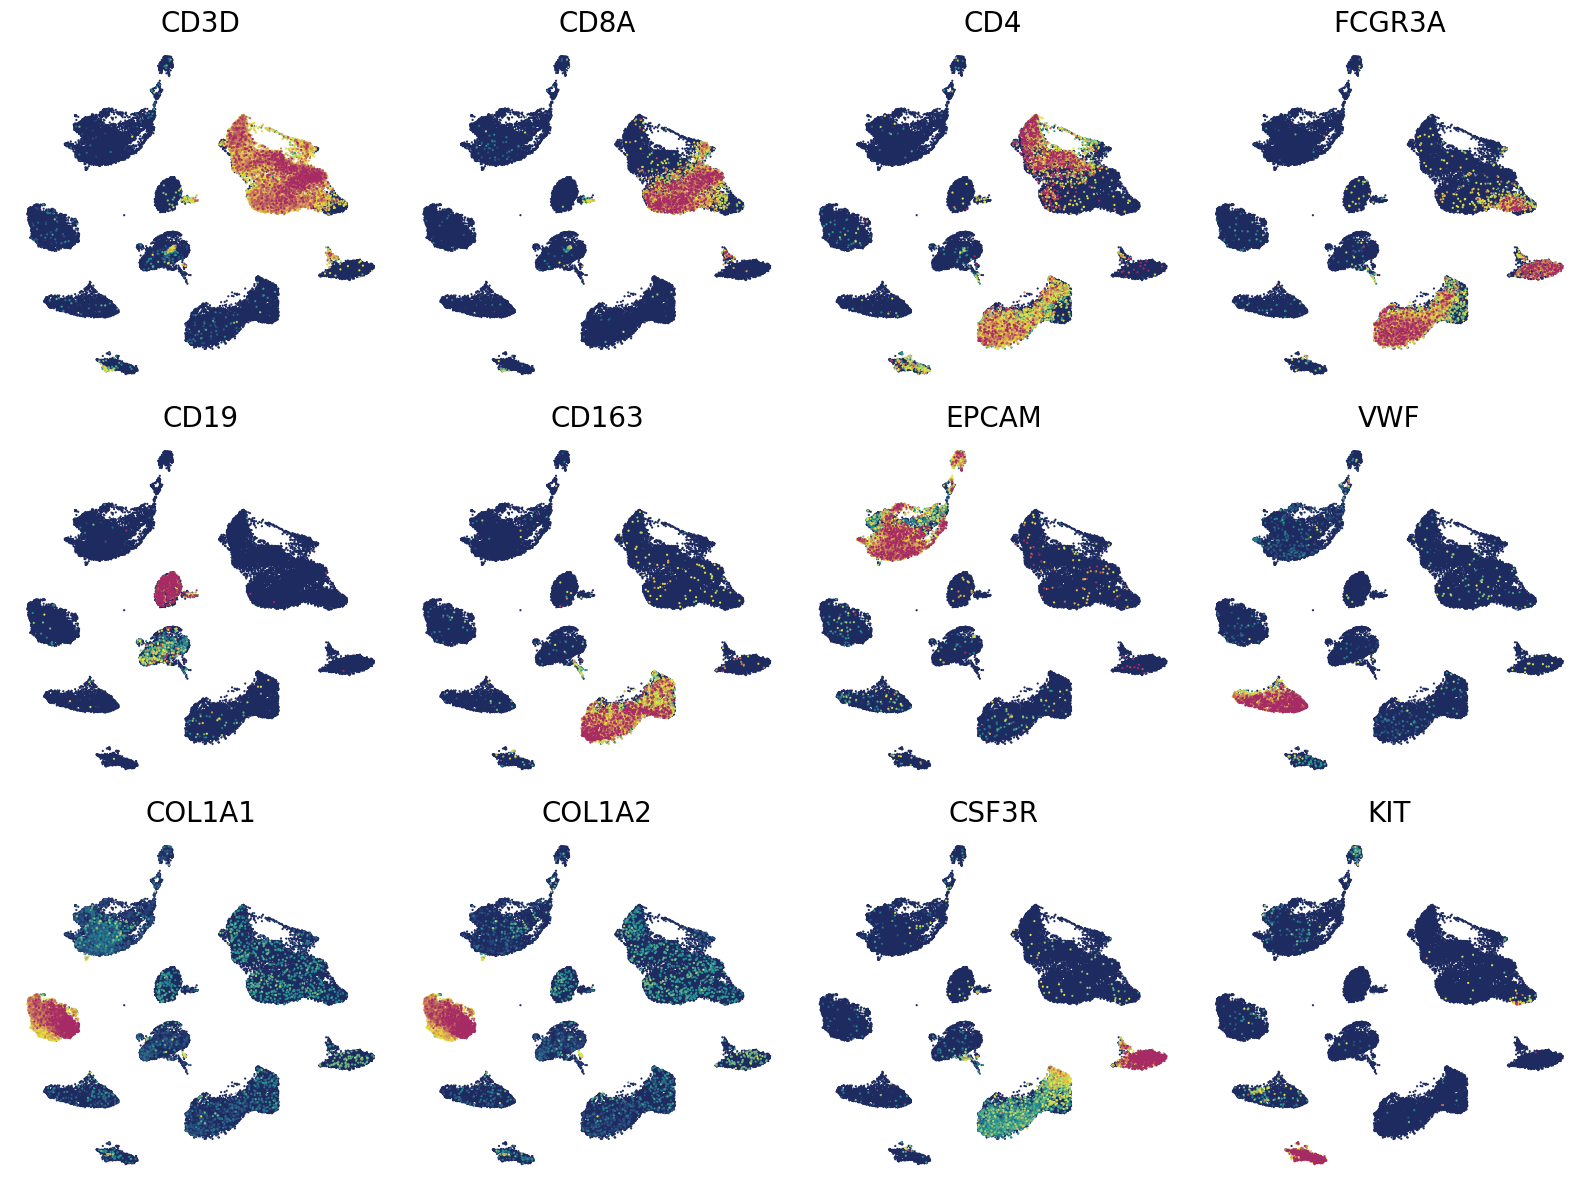

In [ ]:
genes_to_plot = [
    "CD3D",
    "CD8A",
    "CD4",
    "FCGR3A",
    "CD19",
    "CD163",
    "EPCAM",
    "VWF",
    "COL1A1",
    "COL1A2",
    "CSF3R",
    "KIT"
]


import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import math
ncols = 4
nrows = math.ceil(len(genes_to_plot) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(4 * ncols, 4 * nrows)
)

axes = axes.flatten()

for i, gene in enumerate(genes_to_plot):
    ax = axes[i]

    sc.pl.umap(
        adata_all,
        color=gene,
        title=gene,
        ax=ax,
        show=False,
        frameon=False,
        size=10,
        cmap=cmap,
        vmax="p99",colorbar_loc=None
    )

    ax.set_title(gene, fontsize=20)
    # add_umap_arrow_axis(ax, fig, fontsize=9)

# =========================
# =========================
for j in range(len(genes_to_plot), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

plt.savefig(
    "./visum/figure/atlas_marker_gene_umap.tiff",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
adata = sc.read_h5ad("/content/drive/MyDrive/pharynx/1.rawdata/CAF.h5ad")

In [ ]:
adata.obs

                                            orig.ident  nCount_RNA  \
cell_id                                                              
Smoke_1_AAACCTGTCGCGCCAA-smoke1-smoke1         Smoke_1       10361   
Smoke_1_AAACCTGTCTGAAAGA-smoke1-smoke1         Smoke_1        8149   
Smoke_1_AAACGGGCAAGCTGTT-smoke1-smoke1         Smoke_1       10296   
Smoke_1_AAACGGGCATGCCTAA-smoke1-smoke1         Smoke_1        9433   
Smoke_1_AAACGGGGTTAGGGTG-smoke1-smoke1         Smoke_1        9271   
...                                                ...         ...   
NO_3_TTAGGCATCATGGTCA-Non_smoke3-Non_smoke3       NO_3        3485   
NO_3_TTCCCAGGTGTGAAAT-Non_smoke3-Non_smoke3       NO_3        7657   
NO_3_TTCGGTCGTCTTCGTC-Non_smoke3-Non_smoke3       NO_3        2597   
NO_3_TTCTTAGAGTGTACCT-Non_smoke3-Non_smoke3       NO_3        2395   
NO_3_TTGAACGGTTACGCGC-Non_smoke3-Non_smoke3       NO_3        1549   

                                             nFeature_RNA  \
cell_id                     

每组样本数量：
group
No       3
Smoke    3
Name: orig.ident, dtype: int64
Saved: Cycling_CAF


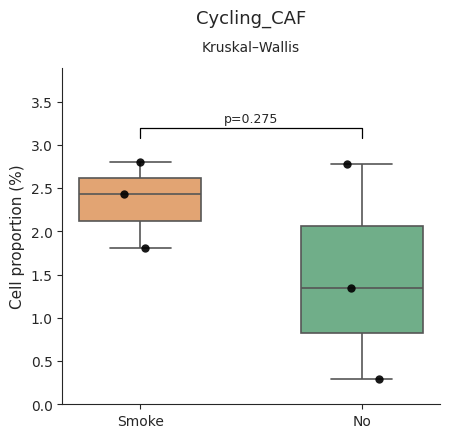

Saved: apCAF


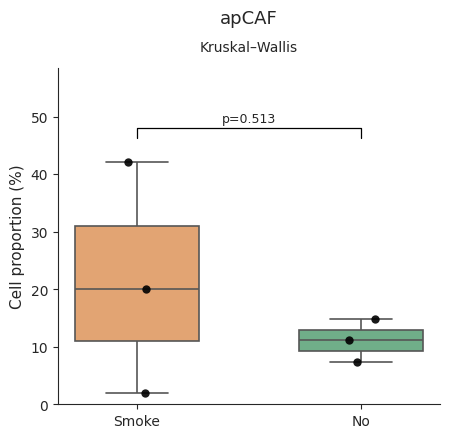

Saved: iCAF_CXCL1


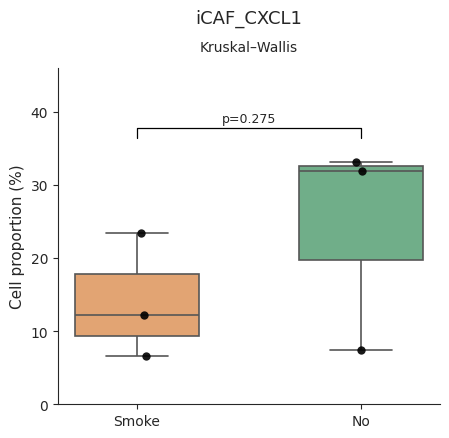

Saved: iCAF_CXCL8


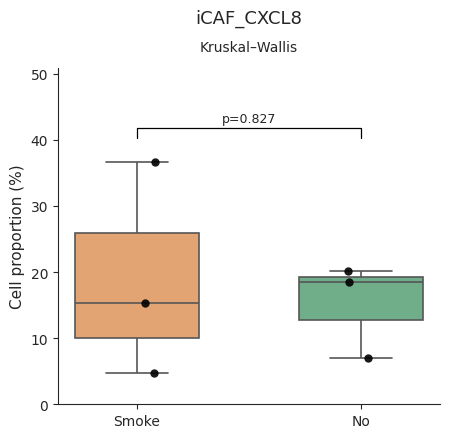

Saved: myCAF_COL14A1


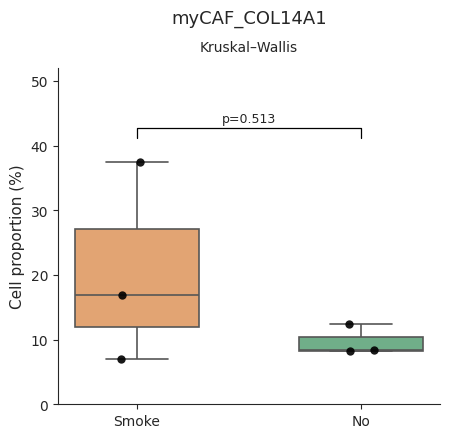

Saved: myCAF_CTHRC1


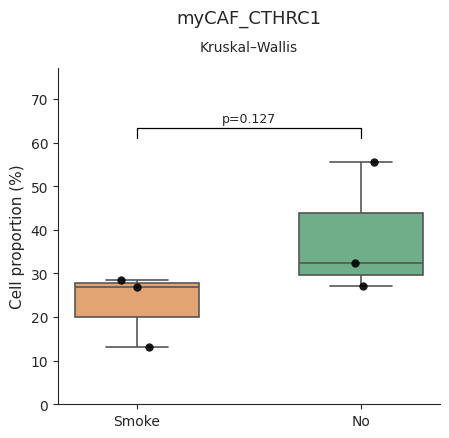

所有 subtype 绘图完成！


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests
from itertools import combinations
from pathlib import Path

# =========================
# =========================
adata.obs["group"] = (
    adata.obs["group"]
    .astype(str)
    .replace({"NO": "No"})
)
GROUPS = ["Smoke", "No"]

group_colors = {
    "No": "#66B887",
    "Smoke": "#F4A261",
}

SAVE = True
OUTDIR = Path("/content/drive/MyDrive/pharynx/visum/figure/")
OUTDIR.mkdir(parents=True, exist_ok=True)

# =========================
# =========================
df = adata.obs[
    ["orig.ident", "group", "subtype"]
].copy()

df = df.dropna()

for col in ["orig.ident", "group", "subtype"]:
    df[col] = df[col].astype(str)

df = df[df["group"].isin(GROUPS)]

sample_meta = df[
    ["orig.ident", "group"]
].drop_duplicates()

if sample_meta["orig.ident"].duplicated().any():
    raise ValueError("同一样本对应多个分组，请检查 group")

print("每组样本数量：")
print(sample_meta.groupby("group")["orig.ident"].nunique())

# =========================
# =========================
counts = pd.crosstab(
    df["orig.ident"],
    df["subtype"]
)

prop = counts.div(
    counts.sum(axis=1),
    axis=0
) * 100

prop.index.name = "orig.ident"

plot_df = (
    prop.reset_index()
    .melt(
        id_vars="orig.ident",
        var_name="subtype",
        value_name="Percentage"
    )
    .merge(sample_meta, on="orig.ident")
)

subtypes = sorted(plot_df["subtype"].unique())

# =========================
# =========================
overall_results = []
pairwise_results = []

def kw_pvalue(*groups):
    all_values = np.concatenate(groups)

    if np.all(all_values == all_values[0]):
        return 1.0

    return kruskal(*groups).pvalue


for subtype in subtypes:

    d = plot_df[
        plot_df["subtype"] == subtype
    ]

    values = {
        g: d.loc[
            d["group"] == g,
            "Percentage"
        ].to_numpy()
        for g in GROUPS
    }

    p_kw = kw_pvalue(
        values["Smoke"],
        values["No"]
    )

    overall_results.append({
        "subtype": subtype,
        "P_KW": p_kw
    })

    for g1, g2 in combinations(GROUPS, 2):

        p = kw_pvalue(
            values[g1],
            values[g2]
        )

        pairwise_results.append({
            "subtype": subtype,
            "group1": g1,
            "group2": g2,
            "P": p
        })

overall_results = pd.DataFrame(overall_results)
pairwise_results = pd.DataFrame(pairwise_results)

overall_results["FDR"] = multipletests(
    overall_results["P_KW"],
    method="fdr_bh"
)[1]

# =========================
# =========================
def format_p(p):
    if p < 0.01:
        return "p<0.01"
    return f"p={p:.3f}"

# =========================
# =========================
import re

sns.set_style("ticks")

for subtype in subtypes:

    d = plot_df[
        plot_df["subtype"] == subtype
    ]

    fig, ax = plt.subplots(figsize=(4.6, 4.5))

    sns.boxplot(
        data=d,
        x="group",
        y="Percentage",
        order=GROUPS,
        hue="group",
        hue_order=GROUPS,
        palette=group_colors,
        width=0.55,
        linewidth=1.2,
        showfliers=False,
        legend=False,
        ax=ax
    )

    sns.stripplot(
        data=d,
        x="group",
        y="Percentage",
        order=GROUPS,
        color="black",
        size=6,
        jitter=0.08,
        alpha=0.9,
        ax=ax
    )

    # =========================
    # =========================
    ax.text(
        0.5, 1.12,
        subtype,
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="normal"
    )

    ax.text(
        0.5, 1.04,
        "Kruskal–Wallis",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="normal"
    )

    # =========================
    # =========================
    ymax = d["Percentage"].max()
    span = max(ymax, 0.1)

    base = ymax + span * 0.10
    h = span * 0.04

    p = pairwise_results.loc[
        (pairwise_results["subtype"] == subtype) &
        (pairwise_results["group1"] == "Smoke") &
        (pairwise_results["group2"] == "No"),
        "P"
    ].iloc[0]

    ax.plot(
        [0, 0, 1, 1],
        [base, base + h, base + h, base],
        color="black",
        linewidth=0.9
    )

    ax.text(
        0.5,
        base + h * 1.3,
        format_p(p),
        ha="center",
        va="bottom",
        fontsize=9
    )

    ax.set_ylim(
        0,
        base + h + span * 0.25
    )

    ax.set_xlabel("")
    ax.set_ylabel(
        "Cell proportion (%)",
        fontsize=11
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    sns.despine(ax=ax)

    plt.tight_layout()

    # =========================
    # =========================
    if SAVE:

        safe_name = re.sub(
            r'[^\w.-]+',
            "_",
            str(subtype)
        )

        fig.savefig(
            OUTDIR / f"{safe_name}_boxplot.tiff",
            dpi=600,
            bbox_inches="tight",
            facecolor="white",
            pil_kwargs={
                "compression": "tiff_lzw"
            }
        )

        fig.savefig(
            OUTDIR / f"{safe_name}_boxplot.pdf",
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"Saved: {safe_name}")
    plt.show()
    plt.close(fig)

print("所有 subtype 绘图完成！")

每组样本数量：
group
No       3
Smoke    3
Name: orig.ident, dtype: int64
Saved: B


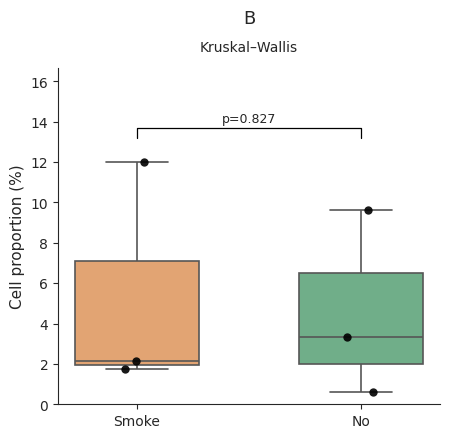

Saved: CAF


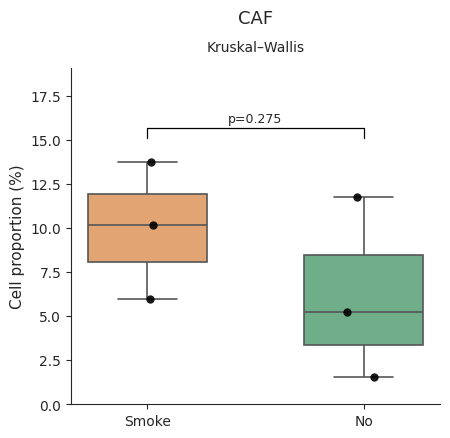

Saved: Endo


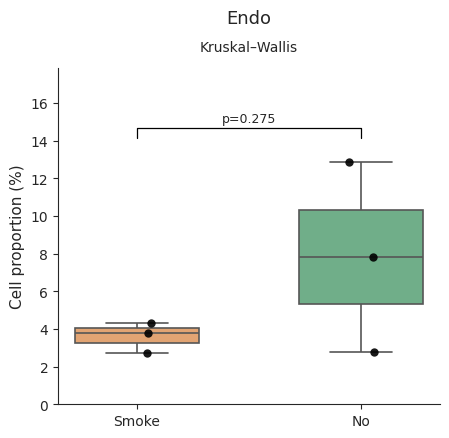

Saved: Epi


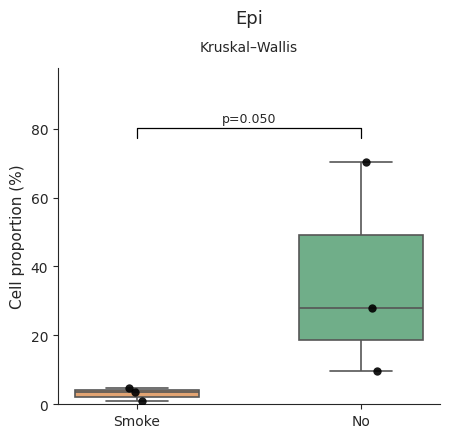

Saved: Mast


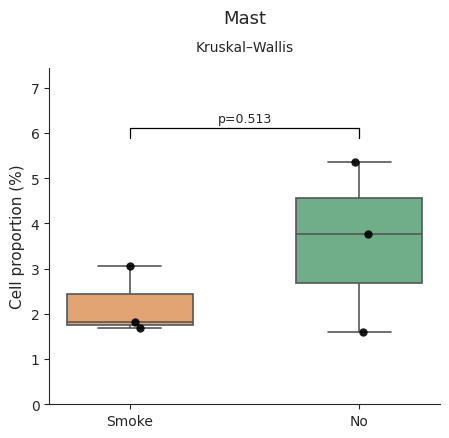

Saved: Myeloid


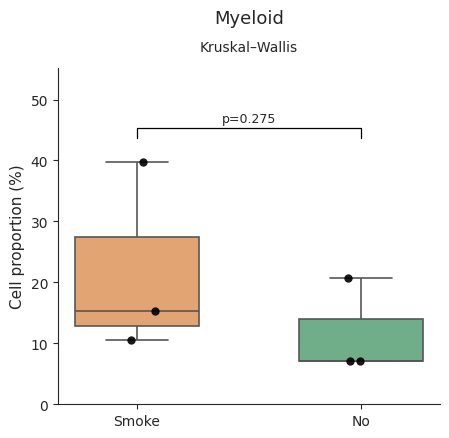

Saved: Neutrophil


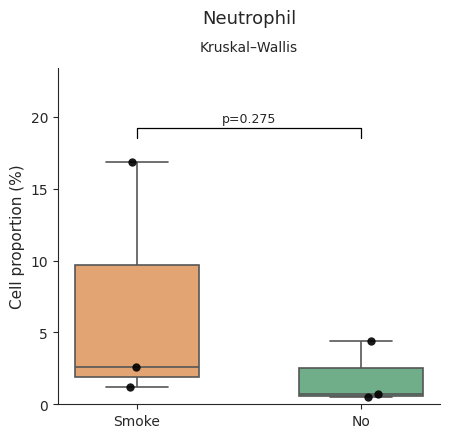

Saved: Plasma


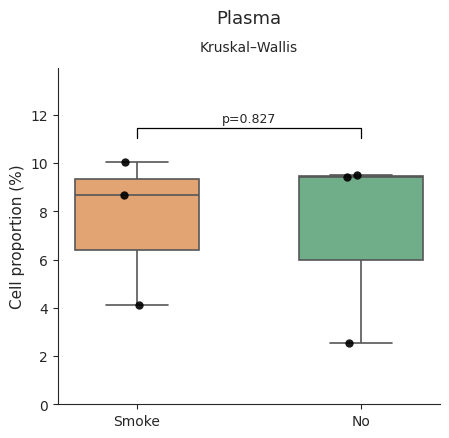

Saved: T_NK


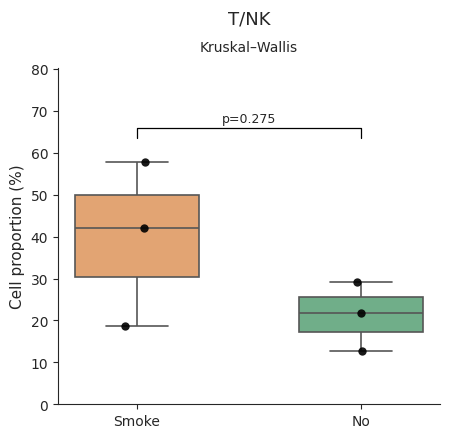

所有 celltype 绘图完成！


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests
from itertools import combinations
from pathlib import Path

# =========================
# =========================
adata_all.obs["group"] = (
    adata_all.obs["group"]
    .astype(str)
    .replace({"NO": "No"})
)
GROUPS = ["Smoke", "No"]

group_colors = {
    "No": "#66B887",
    "Smoke": "#F4A261",
}

SAVE = True
OUTDIR = Path("/content/drive/MyDrive/pharynx/visum/figure/")
OUTDIR.mkdir(parents=True, exist_ok=True)

# =========================
# =========================
df = adata_all.obs[
    ["orig.ident", "group", "celltype"]
].copy()

df = df.dropna()

for col in ["orig.ident", "group", "celltype"]:
    df[col] = df[col].astype(str)

df = df[df["group"].isin(GROUPS)]

sample_meta = df[
    ["orig.ident", "group"]
].drop_duplicates()

if sample_meta["orig.ident"].duplicated().any():
    raise ValueError("同一样本对应多个分组，请检查 group")

print("每组样本数量：")
print(sample_meta.groupby("group")["orig.ident"].nunique())

# =========================
# =========================
counts = pd.crosstab(
    df["orig.ident"],
    df["celltype"]
)

prop = counts.div(
    counts.sum(axis=1),
    axis=0
) * 100

prop.index.name = "orig.ident"

plot_df = (
    prop.reset_index()
    .melt(
        id_vars="orig.ident",
        var_name="celltype",
        value_name="Percentage"
    )
    .merge(sample_meta, on="orig.ident")
)

celltypes = sorted(plot_df["celltype"].unique())

# =========================
# =========================
overall_results = []
pairwise_results = []

def kw_pvalue(*groups):
    all_values = np.concatenate(groups)

    if np.all(all_values == all_values[0]):
        return 1.0

    return kruskal(*groups).pvalue


for celltype in celltypes:

    d = plot_df[
        plot_df["celltype"] == celltype
    ]

    values = {
        g: d.loc[
            d["group"] == g,
            "Percentage"
        ].to_numpy()
        for g in GROUPS
    }

    p_kw = kw_pvalue(
        values["Smoke"],
        values["No"]
    )

    overall_results.append({
        "celltype": celltype,
        "P_KW": p_kw
    })

    for g1, g2 in combinations(GROUPS, 2):

        p = kw_pvalue(
            values[g1],
            values[g2]
        )

        pairwise_results.append({
            "celltype": celltype,
            "group1": g1,
            "group2": g2,
            "P": p
        })

overall_results = pd.DataFrame(overall_results)
pairwise_results = pd.DataFrame(pairwise_results)

overall_results["FDR"] = multipletests(
    overall_results["P_KW"],
    method="fdr_bh"
)[1]

# =========================
# =========================
def format_p(p):
    if p < 0.01:
        return "p<0.01"
    return f"p={p:.3f}"

# =========================
# =========================
import re

sns.set_style("ticks")

for celltype in celltypes:

    d = plot_df[
        plot_df["celltype"] == celltype
    ]

    fig, ax = plt.subplots(figsize=(4.6, 4.5))

    sns.boxplot(
        data=d,
        x="group",
        y="Percentage",
        order=GROUPS,
        hue="group",
        hue_order=GROUPS,
        palette=group_colors,
        width=0.55,
        linewidth=1.2,
        showfliers=False,
        legend=False,
        ax=ax
    )

    sns.stripplot(
        data=d,
        x="group",
        y="Percentage",
        order=GROUPS,
        color="black",
        size=6,
        jitter=0.08,
        alpha=0.9,
        ax=ax
    )

    # =========================
    # =========================
    ax.text(
        0.5, 1.12,
        celltype,
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="normal"
    )

    ax.text(
        0.5, 1.04,
        "Kruskal–Wallis",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="normal"
    )

    # =========================
    # =========================
    ymax = d["Percentage"].max()
    span = max(ymax, 0.1)

    base = ymax + span * 0.10
    h = span * 0.04

    p = pairwise_results.loc[
        (pairwise_results["celltype"] == celltype) &
        (pairwise_results["group1"] == "Smoke") &
        (pairwise_results["group2"] == "No"),
        "P"
    ].iloc[0]

    ax.plot(
        [0, 0, 1, 1],
        [base, base + h, base + h, base],
        color="black",
        linewidth=0.9
    )

    ax.text(
        0.5,
        base + h * 1.3,
        format_p(p),
        ha="center",
        va="bottom",
        fontsize=9
    )

    ax.set_ylim(
        0,
        base + h + span * 0.25
    )

    ax.set_xlabel("")
    ax.set_ylabel(
        "Cell proportion (%)",
        fontsize=11
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    sns.despine(ax=ax)

    plt.tight_layout()

    # =========================
    # =========================
    if SAVE:

        safe_name = re.sub(
            r'[^\w.-]+',
            "_",
            str(celltype)
        )

        fig.savefig(
            OUTDIR / f"{safe_name}_boxplot.tiff",
            dpi=600,
            bbox_inches="tight",
            facecolor="white",
            pil_kwargs={
                "compression": "tiff_lzw"
            }
        )

        fig.savefig(
            OUTDIR / f"{safe_name}_boxplot.pdf",
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"Saved: {safe_name}")
    plt.show()
    plt.close(fig)

print("所有 celltype 绘图完成！")

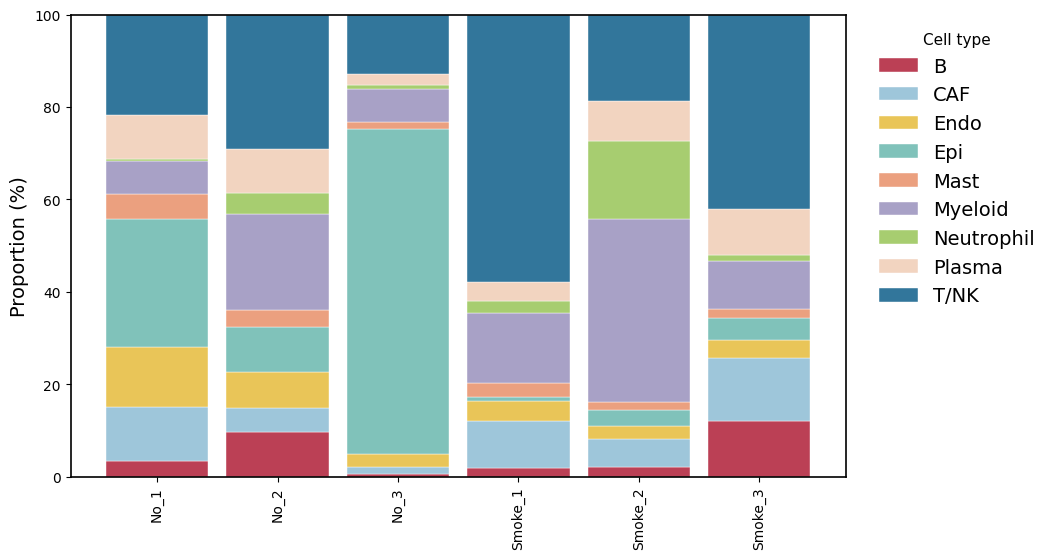

celltype        B    CAF   Endo    Epi  Mast  Myeloid  Neutrophil  Plasma  \
orig.ident                                                                  
No_1         3.35  11.77  12.86  27.81  5.36     7.11        0.48    9.43   
No_2         9.61   5.21   7.82   9.70  3.77    20.79        4.42    9.52   
No_3         0.59   1.52   2.78  70.31  1.61     7.16        0.69    2.56   
Smoke_1      1.77  10.16   4.32   0.88  3.05    15.30        2.59    4.11   
Smoke_2      2.16   5.99   2.73   3.49  1.68    39.74       16.87    8.67   
Smoke_3     12.00  13.73   3.76   4.85  1.82    10.49        1.22   10.04   

celltype     T/NK  
orig.ident         
No_1        21.83  
No_2        29.15  
No_3        12.78  
Smoke_1     57.82  
Smoke_2     18.68  
Smoke_3     42.08  


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# =========================
SAMPLE_COL = "orig.ident"
CELL_COL = "celltype"
GROUP_COL = "group"

GROUPS = ["No", "Smoke"]

palette_major = [
    "#bb4055",
    "#9ec6da",
    "#e9c558",
    "#80c2ba",
    "#eba07f",
    "#a8a1c6",
    "#a7cd70",
    "#f2d4c0",
    "#32769b",
]

group_colors = {
    "No": "#66B887",
    "Smoke": "#F4A261"
}

SAVE = True
OUTDIR = Path("./visum/figure/")
OUTDIR.mkdir(parents=True, exist_ok=True)

# =========================
# =========================
df = adata_all.obs[
    [SAMPLE_COL, CELL_COL, GROUP_COL]
].copy()

df = df.dropna()

for col in [SAMPLE_COL, CELL_COL, GROUP_COL]:
    df[col] = df[col].astype(str)

df[GROUP_COL] = df[GROUP_COL].replace({
    "NO": "No"
})

df = df[df[GROUP_COL].isin(GROUPS)]

# =========================
# =========================
counts = pd.crosstab(
    df[SAMPLE_COL],
    df[CELL_COL]
)

prop = counts.div(
    counts.sum(axis=1),
    axis=0
) * 100

# =========================
# =========================
sample_meta = df[
    [SAMPLE_COL, GROUP_COL]
].drop_duplicates()

if sample_meta[SAMPLE_COL].duplicated().any():
    raise ValueError("同一样本存在多个 group，请检查")

sample_meta["group_order"] = pd.Categorical(
    sample_meta[GROUP_COL],
    categories=GROUPS,
    ordered=True
)

sample_meta = sample_meta.sort_values(
    ["group_order", SAMPLE_COL]
)

sample_order = sample_meta[SAMPLE_COL].tolist()

prop = prop.loc[sample_order]

celltypes = prop.columns.tolist()

if len(celltypes) <= len(palette_major):
    colors = palette_major[:len(celltypes)]
else:
    cmap = plt.get_cmap("tab20", len(celltypes))
    colors = [cmap(i) for i in range(len(celltypes))]

celltype_colors = dict(zip(celltypes, colors))

# =========================
# =========================
fig, ax = plt.subplots(
    figsize=(max(10, len(sample_order) * 0.55), 6)
)

bottom = np.zeros(len(prop))

for celltype in celltypes:

    values = prop[celltype].to_numpy()

    ax.bar(
        np.arange(len(prop)),
        values,
        bottom=bottom,
        width=0.85,
        color=celltype_colors[celltype],
        label=celltype,
        edgecolor="white",
        linewidth=0.3
    )

    bottom += values

# =========================
# =========================
ax.set_xticks(np.arange(len(sample_order)))

ax.set_xticklabels(
    sample_order,
    rotation=90,
    fontsize=14
)

# group_values = sample_meta[GROUP_COL].tolist()

# for i in range(1, len(group_values)):
#     if group_values[i] != group_values[i - 1]:
#         ax.axvline(
#             i - 0.5,
#             color="black",
#             linestyle="--",
#             linewidth=1
#         )

# for group in GROUPS:

#     indices = [
#         i for i, g in enumerate(group_values)
#         if g == group
#     ]

#     if len(indices) == 0:
#         continue

#     center = np.mean(indices)

#     ax.text(
#         center,
#         103,
#         group,
#         ha="center",
#         va="bottom",
#         fontsize=14,
#         color=group_colors[group]
#     )

# =========================
# =========================

ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 20))

ax.set_ylabel(
    "Proportion (%)",
    fontsize=14
)

ax.set_xlabel("")

ax.tick_params(
    axis="both",
    labelsize=10,
    direction="out"
)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

ax.legend(
    title="Cell type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=14,
    title_fontsize=11
)

# =========================
# =========================
if SAVE:

    fig.savefig(
        OUTDIR / "celltype_proportion_by_sample.tiff",
        dpi=600,
        bbox_inches="tight",
        pil_kwargs={
            "compression": "tiff_lzw"
        }
    )

    fig.savefig(
        OUTDIR / "celltype_proportion_by_sample.pdf",
        bbox_inches="tight"
    )

plt.show()

# =========================
# =========================
prop.to_csv(
    OUTDIR / "celltype_proportion_by_sample.csv"
)

print(prop.round(2))

In [ ]:
adata_all.obs["group"]

cell_id
Smoke_1_AAACCTGAGCAGATCG-smoke1-smoke1         Smoke
Smoke_1_AAACCTGAGCGACGTA-smoke1-smoke1         Smoke
Smoke_1_AAACCTGAGCTAGGCA-smoke1-smoke1         Smoke
Smoke_1_AAACCTGAGGAGTCTG-smoke1-smoke1         Smoke
Smoke_1_AAACCTGAGGATGGAA-smoke1-smoke1         Smoke
                                               ...  
NO_3_TTTGTCAGTGTCCTCT-Non_smoke3-Non_smoke3       NO
NO_3_TTTGTCATCCCACTTG-Non_smoke3-Non_smoke3       NO
NO_3_TTTGTCATCCTCAATT-Non_smoke3-Non_smoke3       NO
NO_3_TTTGTCATCGTACCGG-Non_smoke3-Non_smoke3       NO
NO_3_TTTGTCATCTCTAAGG-Non_smoke3-Non_smoke3       NO
Name: group, Length: 40980, dtype: category
Categories (2, object): ['NO', 'Smoke']

每组细胞数量：
group
No       18607
Smoke    22373
dtype: int64


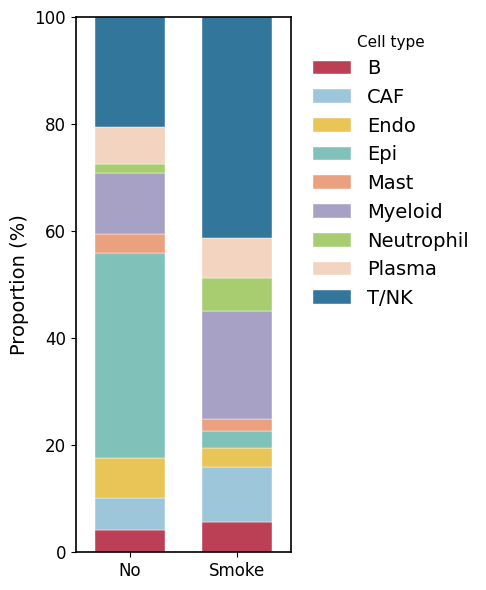

celltype     B    CAF  Endo    Epi  Mast  Myeloid  Neutrophil  Plasma   T/NK
group                                                                       
No        4.22   5.86  7.48  38.44  3.44    11.32        1.77    6.84  20.63
Smoke     5.57  10.29  3.68   3.03  2.23    20.33        6.05    7.52  41.30


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# =========================
CELL_COL = "celltype"
GROUP_COL = "group"

GROUPS = ["No", "Smoke"]

palette_major = [
    "#bb4055",
    "#9ec6da",
    "#e9c558",
    "#80c2ba",
    "#eba07f",
    "#a8a1c6",
    "#a7cd70",
    "#f2d4c0",
    "#32769b",
]

SAVE = True
OUTDIR = Path("./visum/figure/")
OUTDIR.mkdir(parents=True, exist_ok=True)

# =========================
# =========================
df = adata_all.obs[
    [GROUP_COL, CELL_COL]
].copy()

df = df.dropna()

for col in [GROUP_COL, CELL_COL]:
    df[col] = df[col].astype(str).str.strip()

df[GROUP_COL] = df[GROUP_COL].replace({
    "NO": "No"
})

df = df[df[GROUP_COL].isin(GROUPS)]

# =========================
# =========================
counts = pd.crosstab(
    df[GROUP_COL],
    df[CELL_COL]
)

counts = counts.reindex(
    GROUPS,
    fill_value=0
)

prop = counts.div(
    counts.sum(axis=1),
    axis=0
) * 100

print("每组细胞数量：")
print(counts.sum(axis=1))

# =========================
# =========================
celltypes = prop.columns.tolist()

if len(celltypes) <= len(palette_major):
    colors = palette_major[:len(celltypes)]
else:
    cmap = plt.get_cmap("tab20", len(celltypes))
    colors = [cmap(i) for i in range(len(celltypes))]

celltype_colors = dict(zip(celltypes, colors))

# =========================
# =========================
fig, ax = plt.subplots(
    figsize=(5, 6)
)

x = np.arange(len(GROUPS))

bottom = np.zeros(len(GROUPS))

for celltype in celltypes:

    values = prop[celltype].to_numpy()

    ax.bar(
        x,
        values,
        bottom=bottom,
        width=0.65,
        color=celltype_colors[celltype],
        label=celltype,
        edgecolor="white",
        linewidth=0.3
    )

    bottom += values

# =========================
# =========================
ax.set_xticks(x)

ax.set_xticklabels(
    GROUPS,
    fontsize=14
)

ax.set_xlim(-0.5, len(GROUPS) - 0.5)

# =========================
# =========================
ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 20))

ax.set_ylabel(
    "Proportion (%)",
    fontsize=14
)

ax.set_xlabel("")

ax.tick_params(
    axis="both",
    labelsize=12,
    direction="out"
)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

# =========================
# =========================
ax.legend(
    title="Cell type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=14,
    title_fontsize=11
)

plt.tight_layout()

# =========================
# =========================
if SAVE:

    fig.savefig(
        OUTDIR / "celltype_proportion_by_group.tiff",
        dpi=600,
        bbox_inches="tight",
        pil_kwargs={
            "compression": "tiff_lzw"
        }
    )

    fig.savefig(
        OUTDIR / "celltype_proportion_by_group.pdf",
        bbox_inches="tight"
    )

plt.show()

# =========================
# =========================
prop.to_csv(
    OUTDIR / "celltype_proportion_by_group.csv"
)

print(prop.round(2))

# end